# L2 — Classification with XGBoost (Ames Housing)

**Task.** We predict the price class of each house with a multiclass XGBoost model. There are six classes:

| Class | Price range |
|---|---|
| 0 | < 100 000 |
| 1 | 100 000 – 130 000 |
| 2 | 130 000 – 180 000 |
| 3 | 180 000 – 250 000 |
| 4 | 250 000 – 400 000 |
| 5 | ≥ 400 000 |

The main metric is **macro-F1**, the unweighted mean of the per-class F1 scores. Every class counts equally, so the rare `≥400k` class matters as much as the large `130–180k` class.

**Contents.**
1. Data loading, target, and class imbalance
2. Data cleaning and encoding strategies
3. Train/test splits (10 % vs 20 %, with and without stratification) and k-fold CV (k = 5, 10), with a bias–variance discussion
4. Comparison of data-preparation strategies and class-imbalance methods
5. Manual hyperparameter experiments
6. Bayesian optimisation with Optuna (TPESampler, SQLite storage)
7. Final model: metrics, confusion matrix, ROC and PR curves, first and best tree, feature importance
8. Decision thresholds that maximise macro-F1
9. **Bonus:** CatBoost compared with XGBoost
10. Conclusions

The shared, target-free preprocessing code is in `l2_utils.py`. XGBoost and CatBoost therefore receive exactly the same features.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import optuna
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize

import l2_utils as U

SEED = 42
N_CLASSES = 6
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
print("xgboost", xgb.__version__, "| optuna", optuna.__version__)

xgboost 3.4.1 | optuna 5.0.0


## 1. Data and target

,Class,Count,Share %
0,<100k,237,8.09
1,100-130k,509,17.37
2,130-180k,1037,35.39
3,180-250k,686,23.41
4,250-400k,397,13.55
5,>=400k,64,2.18


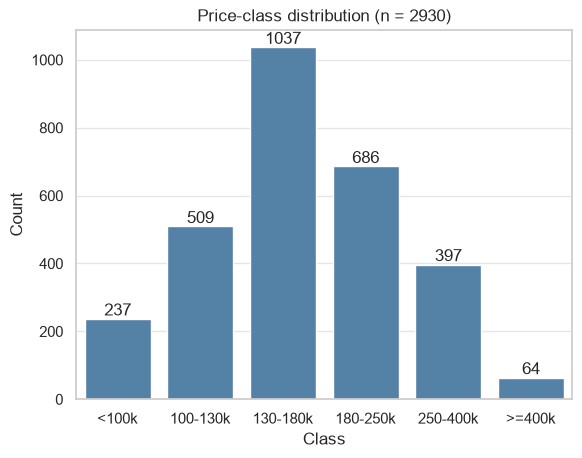

In [2]:
df = U.load_data()
y_all = U.make_target(df["SalePrice"]).to_numpy()
log_price_all = np.log(df["SalePrice"].to_numpy())

counts = pd.Series(y_all).value_counts().sort_index()
dist = pd.DataFrame({"Class": U.CLASS_NAMES, "Count": counts.values,
                     "Share %": (100 * counts / counts.sum()).round(2).values})
display(dist)

ax = sns.barplot(data=dist, x="Class", y="Count", color="steelblue")
ax.set_title("Price-class distribution (n = %d)" % len(df))
for i, c in enumerate(dist["Count"]):
    ax.text(i, c + 10, str(c), ha="center")
plt.show()

The classes are **imbalanced**. `130–180k` holds about 35 % of the houses and `≥400k` only about 2 % (64 houses). This affects the study in three ways:
* *accuracy* alone is misleading, so we report macro-F1;
* splits should be **stratified**, otherwise a 10 % test set may contain only a handful of `≥400k` houses;
* class-imbalance methods can help: class weights, and moving the decision thresholds (sections 4 and 8).

## 2. Data cleaning and encoding

The EDA notebooks found the following issues. `l2_utils.clean` fixes them:

| Problem | Treatment |
|---|---|
| `Order`, `PID` are identifiers | dropped |
| NA in `Alley`, `Pool QC`, `Fence`, `Bsmt*`, `Garage*`, `Fireplace Qu`, `Misc Feature`, `Mas Vnr Type` means *the house does not have this feature* | filled with the category `"None"` (areas and counts filled with 0) |
| `Lot Frontage` has 490 missing values | filled with the neighbourhood median, which is close to the true value |
| `Garage Yr Blt` = 2207 (typo) and missing values for houses without a garage | 2207 → 2007; missing → `Year Built` |
| `MS SubClass` is stored as a number but is nominal | converted to a string |
| 3 partial sales with > 4000 sq ft and an unusually low price (see EDA) | removed **from training data only** (`U.outlier_mask`) |

**Encoding.** We compare three strategies:
* **label**: every categorical column gets arbitrary integer codes. This is a naive baseline: the integers impose an order that does not exist for nominal columns, and the real order of quality scales is lost.
* **onehot**: quality-type scales (Po < Fa < TA < Gd < Ex, BsmtFin types, `Functional`, …) are mapped to integers that respect their order; nominal columns get one-hot dummies.
* **native**: ordinal columns as above; nominal columns use the pandas `category` dtype and XGBoost's native categorical splits (`enable_categorical=True`).

**Feature engineering** (`U.add_features`) adds total and finished area, house age, years since remodel, total bathrooms, total porch area, quality × area interactions, has-2nd-floor/garage/fireplace flags, and quality × size scores.

In [3]:
X_label  = U.prepare(df, "label")
X_onehot_raw = U.prepare(df, "onehot", features=False)
X_onehot = U.prepare(df, "onehot", features=True)
X_native = U.prepare(df, "native", features=True)
outliers = U.outlier_mask(df)

for name, X in [("label", X_label), ("onehot (no FE)", X_onehot_raw), ("onehot + FE", X_onehot), ("native + FE", X_native)]:
    print(f"{name:16s} shape={X.shape}  missing={int(X.isna().sum().sum())}")
print("training outliers removed per fit:", outliers.sum())

label            shape=(2930, 79)  missing=0
onehot (no FE)   shape=(2930, 250)  missing=0
onehot + FE      shape=(2930, 268)  missing=0
native + FE      shape=(2930, 97)  missing=0
training outliers removed per fit: 3


## 3. Splits, stratification, and k-fold cross-validation

A baseline XGBoost classifier (fixed parameters, *onehot + FE* features) is evaluated with several protocols:
* single hold-out split with a 10 % or 20 % test set, with and without stratification. Each protocol is repeated over 10 random seeds so we can measure how much the score varies between splits;
* k-fold CV with k = 5 and k = 10, using `KFold` and `StratifiedKFold`.

In [4]:
BASE_PARAMS = dict(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8,
                   colsample_bytree=0.5, min_child_weight=1, tree_method="hist",
                   n_jobs=-1, random_state=0)

def fit_predict(X_tr, y_tr, X_va, params=BASE_PARAMS, weight_power=1.0, drop_outliers=None):
    # Remove outliers from the training part only, then fit and return class probabilities.
    if drop_outliers is not None:
        keep = ~drop_outliers
        X_tr, y_tr = X_tr[keep], y_tr[keep]
    sw = compute_sample_weight("balanced", y_tr) ** weight_power if weight_power else None
    model = xgb.XGBClassifier(**params).fit(X_tr, y_tr, sample_weight=sw)
    return model, model.predict_proba(X_va)

def run_cv(X, y, splitter, params=BASE_PARAMS, weight_power=1.0, return_oof=False):
    scores, train_scores = [], []
    oof = np.zeros((len(y), N_CLASSES))
    for tr, va in splitter.split(X, y):
        model, p = fit_predict(X.iloc[tr], y[tr], X.iloc[va], params, weight_power, outliers[tr])
        oof[va] = p
        scores.append(U.macro_f1(y[va], p.argmax(1)))
        train_scores.append(U.macro_f1(y[tr], model.predict(X.iloc[tr])))
    res = dict(mean=np.mean(scores), std=np.std(scores), train=np.mean(train_scores), folds=scores)
    return (res, oof) if return_oof else res

In [5]:
rows = []
for test_size in [0.10, 0.20]:
    for strat in [False, True]:
        scores, n_top = [], []
        for seed in range(10):
            idx_tr, idx_te = train_test_split(np.arange(len(y_all)), test_size=test_size,
                                              random_state=seed, stratify=y_all if strat else None)
            _, p = fit_predict(X_onehot.iloc[idx_tr], y_all[idx_tr], X_onehot.iloc[idx_te],
                               drop_outliers=outliers[idx_tr])
            scores.append(U.macro_f1(y_all[idx_te], p.argmax(1)))
            n_top.append((y_all[idx_te] == 5).sum())
        rows.append({"protocol": f"hold-out {int(test_size*100)}%", "stratified": strat,
                     "macro-F1 mean": np.mean(scores), "macro-F1 std": np.std(scores),
                     "min": np.min(scores), "max": np.max(scores),
                     "#>=400k in test (min-max)": f"{min(n_top)}-{max(n_top)}"})
holdout_df = pd.DataFrame(rows)
display(holdout_df.round(4))

,protocol,stratified,macro-F1 mean,macro-F1 std,min,max,#>=400k in test (min-max)
0,hold-out 10%,False,0.7801,0.0205,0.7439,0.8172,3-11
1,hold-out 10%,True,0.7711,0.0234,0.7292,0.8111,6-6
2,hold-out 20%,False,0.7747,0.0137,0.7540,0.7961,8-18
3,hold-out 20%,True,0.7703,0.0198,0.7356,0.7952,13-13


In [6]:
rows = []
for k in [5, 10]:
    for strat in [False, True]:
        splitter = (StratifiedKFold if strat else KFold)(k, shuffle=True, random_state=SEED)
        r = run_cv(X_onehot, y_all, splitter)
        rows.append({"protocol": f"{k}-fold", "stratified": strat, "macro-F1 mean": r["mean"],
                     "macro-F1 std (across folds)": r["std"], "train macro-F1": r["train"]})
cv_df = pd.DataFrame(rows)
display(cv_df.round(4))

,protocol,stratified,macro-F1 mean,macro-F1 std (across folds),train macro-F1
0,5-fold,False,0.7595,0.0229,0.9831
1,5-fold,True,0.7700,0.0138,0.9826
2,10-fold,False,0.7611,0.0309,0.9797
3,10-fold,True,0.7678,0.0262,0.9797


### Interpretation: splits, stratification, bias–variance

* **10 % vs 20 % hold-out.** A 10 % test set holds about 290 houses and only about 6 of them are `≥400k`. One misclassified luxury house changes that class's F1 by about 0.1, so the 10 % estimate has **higher variance** between seeds (larger std and min–max range). The 20 % split gives a more stable estimate. It costs a little training data, which adds a small pessimistic **bias**.
* **Stratification** keeps the class proportions equal in train and test. Without it, the number of `≥400k` houses in the test set changes a lot from seed to seed (last column), which makes macro-F1 noisier. Stratified versions usually have a lower std; the mean barely changes.
* **k = 5 vs k = 10.** With k = 10 each model trains on 90 % of the data instead of 80 %, so the CV estimate is *less pessimistically biased*. Each validation fold is smaller (about 290 vs 586 rows), so the per-fold scores vary more (higher std across folds), and the run takes twice as long. Both give nearly the same mean, so we use **stratified 5-fold CV** for model selection. It is a good bias/variance/cost compromise.
* **Train vs validation.** The train macro-F1 is close to 1.0 while validation is around 0.77. Boosted trees with 600 rounds fit the training set almost perfectly. The gap shows the model's **variance**: it memorises noise near the class borders. Regularisation (depth, `min_child_weight`, subsampling, λ) and early stopping control this; see sections 5–6.

## 4. Data-preparation strategies and class imbalance

All variants use stratified 5-fold CV with identical folds. For class imbalance we compare:
* **no weights**;
* **balanced sample weights** $w_c = \frac{n}{K\, n_c}$, so each class contributes the same total weight to the loss;
* **softened weights** $w_c^{0.5}$, a compromise between the two.

A *decision-threshold* adjustment, the other imbalance method from the lecture, is covered in section 8.

The last strategy, **stacking**, addresses a structural weakness of the classifier. The six classes are **ordered price intervals**, but the multiclass soft-max objective treats them as unordered labels. Predicting `250–400k` for a `<100k` house is penalised exactly as much as predicting `100–130k`. We therefore train an XGBoost *regressor* on log(SalePrice) and give its out-of-fold prediction to the classifier as an extra feature, `Price Estimate` (`U.add_price_estimate`). The classifier still makes the final decision. The regressor contributes the ordinal and continuous structure of the target. Within each CV fold the regressor is trained **only on that fold's training rows**, and the classifier's training rows receive out-of-fold estimates, so no target information leaks.

In [7]:
skf5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

def run_cv_stacked(X, y, params=BASE_PARAMS, weight_power=1.0):
    # CV in which the Price Estimate feature is rebuilt inside every training fold.
    scores, oof = [], np.zeros((len(y), N_CLASSES))
    for tr, va in skf5.split(X, y):
        tr = tr[~outliers[tr]]
        Xtr, Xva = U.add_price_estimate(X.iloc[tr], log_price_all[tr], X.iloc[va])
        _, p = fit_predict(Xtr, y[tr], Xva, params, weight_power)
        oof[va] = p
        scores.append(U.macro_f1(y[va], p.argmax(1)))
    return dict(mean=np.mean(scores), std=np.std(scores)), oof

experiments = [
    ("label encoding",          X_label,      dict(), None),
    ("onehot, no FE",           X_onehot_raw, dict(), None),
    ("onehot + FE",             X_onehot,     dict(), None),
    ("onehot + FE",             X_onehot,     dict(), 0.5),
    ("onehot + FE",             X_onehot,     dict(), 1.0),
    ("native cat + FE",         X_native,     dict(enable_categorical=True), None),
    ("native cat + FE",         X_native,     dict(enable_categorical=True), 1.0),
]
rows = []
for name, X, extra, wp in experiments:
    r = run_cv(X, y_all, skf5, params={**BASE_PARAMS, **extra}, weight_power=wp)
    rows.append({"features": name, "class weights": {None: "none", 0.5: "sqrt-balanced", 1.0: "balanced"}[wp],
                 "CV macro-F1": r["mean"], "std": r["std"]})
for wp in [None, 1.0]:
    r, _ = run_cv_stacked(X_onehot, y_all, weight_power=wp)
    rows.append({"features": "onehot + FE + Price Estimate (stacking)",
                 "class weights": "none" if wp is None else "balanced", "CV macro-F1": r["mean"], "std": r["std"]})
strategy_df = pd.DataFrame(rows)
display(strategy_df.round(4))

,features,class weights,CV macro-F1,std
0,label encoding,none,0.7411,0.0092
1,"onehot, no FE",none,0.7464,0.0117
2,onehot + FE,none,0.7555,0.0213
3,onehot + FE,sqrt-balanced,0.7605,0.0173
4,onehot + FE,balanced,0.7700,0.0138
5,native cat + FE,none,0.7593,0.0244
6,native cat + FE,balanced,0.7654,0.0109
7,onehot + FE + Price Estimate (stacking),none,0.7879,0.0171
8,onehot + FE + Price Estimate (stacking),balanced,0.7911,0.0116


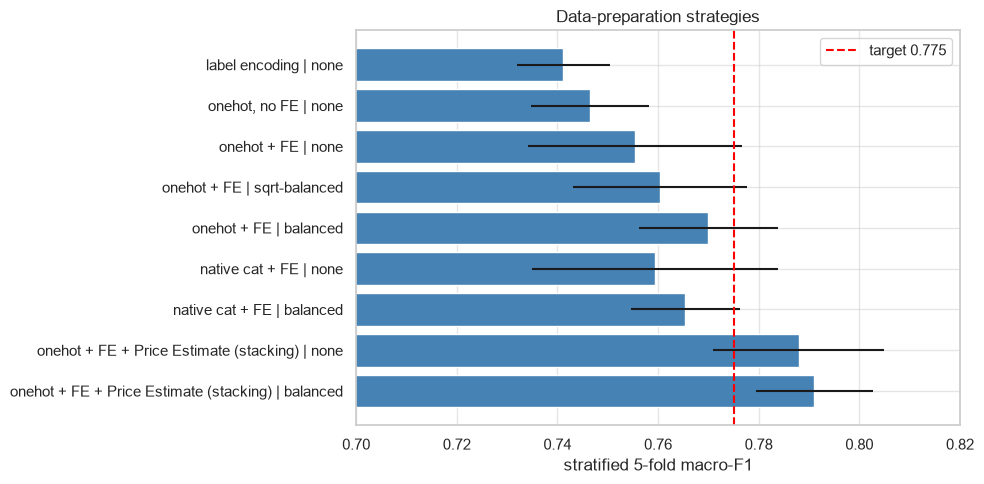

In [8]:
plt.figure(figsize=(10, 5))
lbl = strategy_df["features"] + " | " + strategy_df["class weights"]
plt.barh(lbl, strategy_df["CV macro-F1"], xerr=strategy_df["std"], color="steelblue")
plt.axvline(0.775, color="red", ls="--", label="target 0.775")
plt.xlim(0.70, 0.82); plt.xlabel("stratified 5-fold macro-F1"); plt.legend()
plt.title("Data-preparation strategies"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

### Interpretation

* **Label encoding** is the weakest. Arbitrary integer codes for nominal columns force the trees to make many splits to isolate a single neighbourhood, and the natural order of the quality scales is lost.
* **Ordinal mapping + one-hot** improves results. Quality scales become monotone numeric features, so one split can separate "Gd/Ex" from "TA and below".
* **Feature engineering** adds the largest gain among the plain variants. Total area and quality × area combine the two strongest drivers from the EDA (`Overall Qual`, `Gr Liv Area`) into single features that a shallow tree can use directly.
* **Native categorical** splits score about the same as one-hot, because the only high-cardinality nominal column is `Neighborhood`.
* **Balanced class weights** mainly increase recall of the small classes (`<100k`, `≥400k`), which raises macro-F1 even though accuracy can drop slightly.
* **Stacking with Price Estimate** gives the biggest gain, to about **0.79**. Most errors are between *neighbouring* classes, for example a house at 178k predicted as `180–250k`. A regressor that knows the target is continuous and ordered places the house much more precisely on the price axis than six independent one-vs-rest score functions.

The final pipeline is **onehot + FE + Price Estimate, balanced weights**.

## 5. Manual hyperparameter experiments

From here on we fix a **stratified 80/20 train/test split**. The test set is used only once, in section 7. All tuning uses CV inside the training set. To keep the experiments fast, the `Price Estimate` feature is computed once for the whole training set out-of-fold, and once for the test set by a regressor trained on the full training set.

We vary one hyperparameter at a time around the baseline and plot train and validation macro-F1. This shows directly where the model moves from under- to over-fitting.

In [9]:
idx_train, idx_test = train_test_split(np.arange(len(y_all)), test_size=0.2, random_state=SEED, stratify=y_all)
idx_train = idx_train[~outliers[idx_train]]
X_train, X_test = U.add_price_estimate(X_onehot.iloc[idx_train], log_price_all[idx_train], X_onehot.iloc[idx_test])
y_train, y_test = y_all[idx_train], y_all[idx_test]
w_train = compute_sample_weight("balanced", y_train)
cv_folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_train, y_train))
print("train", X_train.shape, "test", X_test.shape)
print("test class counts:", np.bincount(y_test))

def cv_score(params, X=X_train, y=y_train, return_oof=False):
    oof = np.zeros((len(y), N_CLASSES)); va_s, tr_s = [], []
    for tr, va in cv_folds:
        m = xgb.XGBClassifier(**params).fit(X.iloc[tr], y[tr], sample_weight=compute_sample_weight("balanced", y[tr]))
        oof[va] = m.predict_proba(X.iloc[va])
        va_s.append(U.macro_f1(y[va], oof[va].argmax(1)))
        tr_s.append(U.macro_f1(y[tr], m.predict(X.iloc[tr])))
    out = dict(val=np.mean(va_s), val_std=np.std(va_s), train=np.mean(tr_s))
    return (out, oof) if return_oof else out

train (2343, 269) test (586, 269)
test class counts: [ 48 102 207 137  79  13]


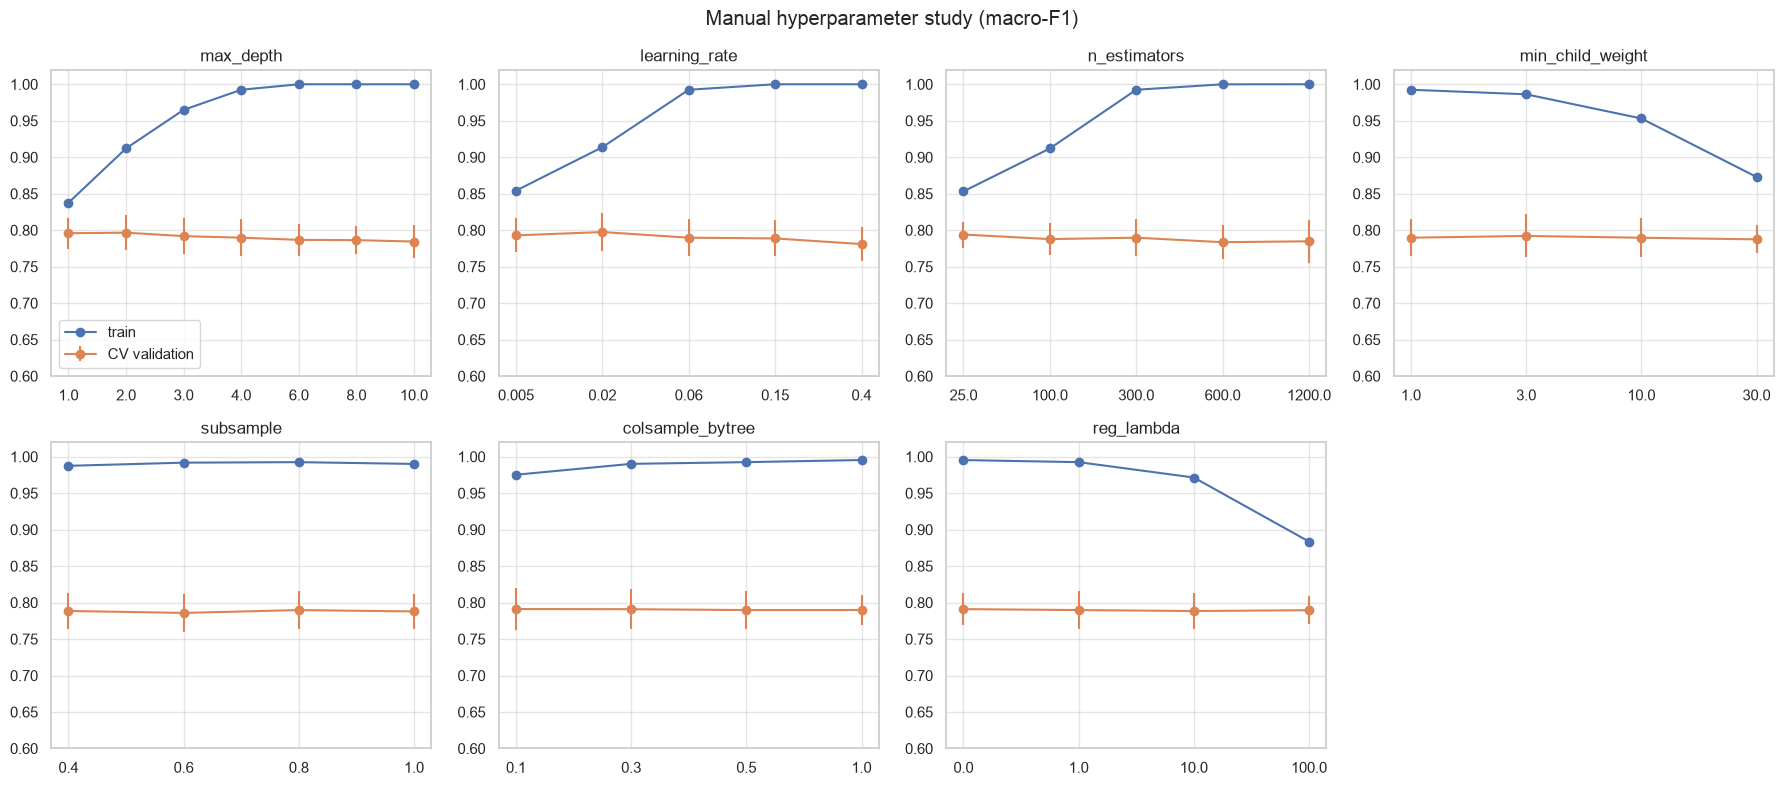

,param,value,val,val_std,train
0,max_depth,1.000,0.7958,0.0210,0.8376
1,max_depth,2.000,0.7966,0.0239,0.9121
2,max_depth,3.000,0.7918,0.0248,0.9649
3,max_depth,4.000,0.7897,0.0257,0.9925
4,max_depth,6.000,0.7867,0.0218,1.0000
5,max_depth,8.000,0.7863,0.0195,1.0000
6,max_depth,10.000,0.7844,0.0228,1.0000
7,learning_rate,0.005,0.7929,0.0234,0.8542
8,learning_rate,0.020,0.7974,0.0259,0.9137
9,learning_rate,0.060,0.7897,0.0257,0.9925


In [10]:
MANUAL_BASE = {**BASE_PARAMS, "n_estimators": 300, "learning_rate": 0.06}
grid = {
    "max_depth":        [1, 2, 3, 4, 6, 8, 10],
    "learning_rate":    [0.005, 0.02, 0.06, 0.15, 0.4],
    "n_estimators":     [25, 100, 300, 600, 1200],
    "min_child_weight": [1, 3, 10, 30],
    "subsample":        [0.4, 0.6, 0.8, 1.0],
    "colsample_bytree": [0.1, 0.3, 0.5, 1.0],
    "reg_lambda":       [0, 1, 10, 100],
}
manual = []
for param, values in grid.items():
    for v in values:
        r = cv_score({**MANUAL_BASE, param: v})
        manual.append({"param": param, "value": v, **r})
manual_df = pd.DataFrame(manual)

fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, (param, g) in zip(axes, manual_df.groupby("param", sort=False)):
    x = np.arange(len(g))
    ax.plot(x, g["train"], "o-", label="train")
    ax.errorbar(x, g["val"], yerr=g["val_std"], fmt="o-", label="CV validation")
    ax.set_xticks(x); ax.set_xticklabels(g["value"]); ax.set_title(param); ax.set_ylim(0.6, 1.02)
axes[0].legend(); axes[-1].axis("off")
plt.suptitle("Manual hyperparameter study (macro-F1)"); plt.tight_layout(); plt.show()
display(manual_df.round(4))

### Interpretation

* **`max_depth`.** Depth 1–2 *underfits* (stumps cannot model interactions such as quality × neighbourhood), so train and validation are both low: high bias. With deeper trees the training score quickly reaches 1.0 while validation flattens and then falls. The extra capacity only memorises noise, so variance grows. The best range is depth 3–4.
* **`learning_rate` × `n_estimators`.** These two work together, since the total amount of fitting is roughly their product. A tiny learning rate or very few trees underfits. A large learning rate (0.4) takes big, noisy steps and overfits quickly. Small steps with many trees generalise best, which is why the final model uses early stopping.
* **`min_child_weight`.** Larger values forbid leaves backed by few (weighted) samples. This regularises, but too much hurts the small `≥400k` class, whose samples are needed to form their own leaves.
* **`subsample` / `colsample_bytree`.** Row and column subsampling decorrelate the trees (the bagging idea) and reduce variance. Very low values (0.1 of the columns) starve the model of the strongest features.
* **`reg_lambda`** (L2 on leaf weights) shrinks leaf values. Moderate values help slightly; λ = 100 underfits.

The train–validation gap stays large for most settings. With only about 2300 training rows, the model's variance, not its bias, is the main limit.

## 6. Bayesian optimisation with Optuna (TPESampler)

**TPE** (Tree-structured Parzen Estimator) is a sequential model-based (Bayesian) optimiser. After a few random start-up trials it splits the finished trials into "good" (top γ quantile) and "bad". It fits two densities $l(x)$ (good) and $g(x)$ (bad) over the hyperparameters and proposes the next point by maximising $l(x)/g(x)$, which corresponds to the expected improvement. Search therefore concentrates where good configurations were found, while still exploring.

* Objective: stratified 5-fold CV macro-F1 on the training set (balanced weights, same folds as above).
* `n_estimators` is chosen by **early stopping** on each validation fold (`mlogloss`, patience 100). Trials that are clearly worse are **pruned** by `MedianPruner` after the first folds.
* Intermediate results are saved in an **SQLite RDB storage** (`optuna_l2.db`). A study can be stopped and resumed (`load_if_exists=True`), and each finished trial is persisted.

In [11]:
STORAGE = "sqlite:///optuna_l2.db"
N_TRIALS_XGB = 60

def xgb_objective(trial):
    params = dict(
        n_estimators=3000, tree_method="hist", n_jobs=-1, random_state=0,
        early_stopping_rounds=100, eval_metric="mlogloss",
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        min_child_weight=trial.suggest_float("min_child_weight", 0.5, 20, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.15, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 50, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        gamma=trial.suggest_float("gamma", 1e-3, 5, log=True),
    )
    weight_power = trial.suggest_float("weight_power", 0.0, 1.0)
    scores, iters = [], []
    for i, (tr, va) in enumerate(cv_folds):
        sw = compute_sample_weight("balanced", y_train[tr]) ** weight_power
        m = xgb.XGBClassifier(**params).fit(X_train.iloc[tr], y_train[tr], sample_weight=sw,
                                            eval_set=[(X_train.iloc[va], y_train[va])], verbose=False)
        scores.append(U.macro_f1(y_train[va], m.predict(X_train.iloc[va])))
        iters.append(m.best_iteration + 1)
        trial.report(np.mean(scores), i)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("n_estimators", int(np.mean(iters)))
    return np.mean(scores)

optuna.logging.set_verbosity(optuna.logging.WARNING)
study_xgb = optuna.create_study(study_name="l2_xgb", storage=STORAGE, load_if_exists=True, direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=12),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1))
remaining = N_TRIALS_XGB - len([t for t in study_xgb.trials if t.state.is_finished()])
if remaining > 0:
    study_xgb.optimize(xgb_objective, n_trials=remaining)
print("best CV macro-F1:", round(study_xgb.best_value, 4))
print("best params:", study_xgb.best_params, "| n_estimators:", study_xgb.best_trial.user_attrs["n_estimators"])

best CV macro-F1: 0.8048
best params: {'learning_rate': 0.015298758309748525, 'max_depth': 2, 'min_child_weight': 3.4817771216680744, 'subsample': 0.566209278458617, 'colsample_bytree': 0.9965728862632095, 'reg_lambda': 0.003537025244238945, 'reg_alpha': 0.5401691970144042, 'gamma': 0.43208559122588075, 'weight_power': 0.3061373840148669} | n_estimators: 544


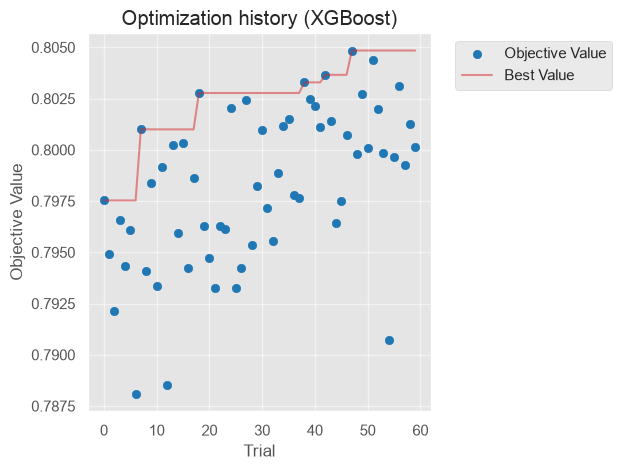

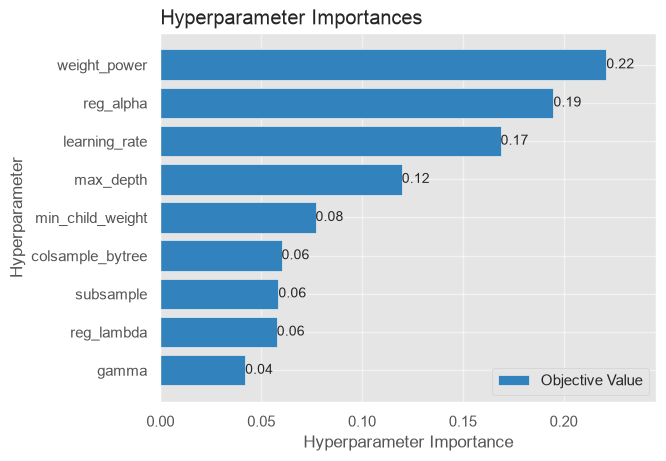

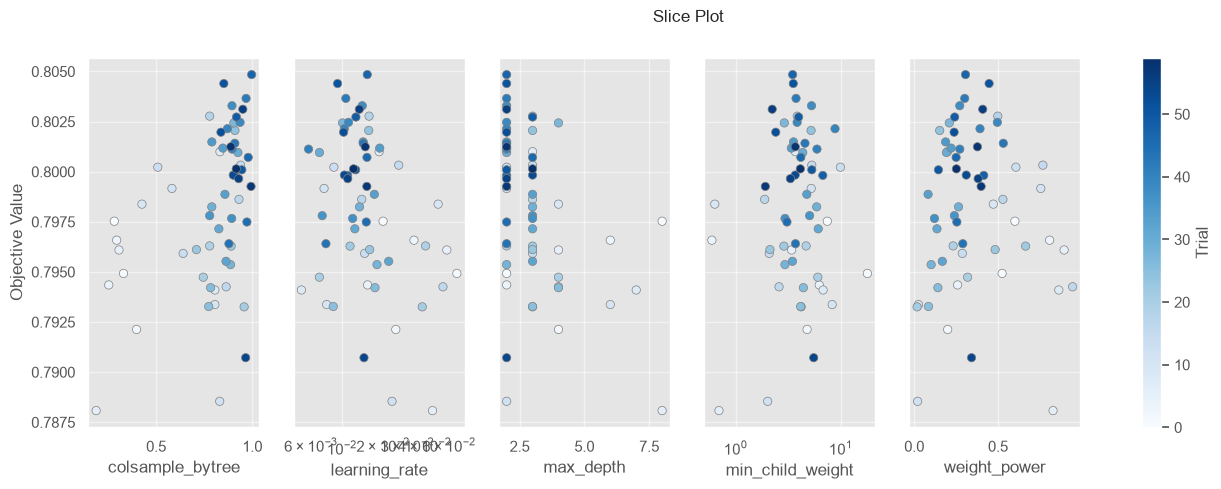

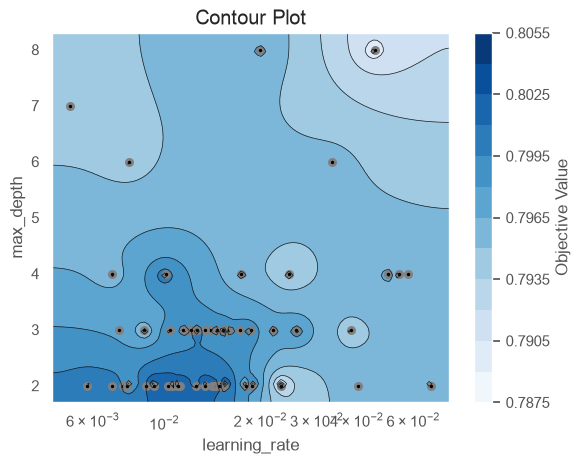

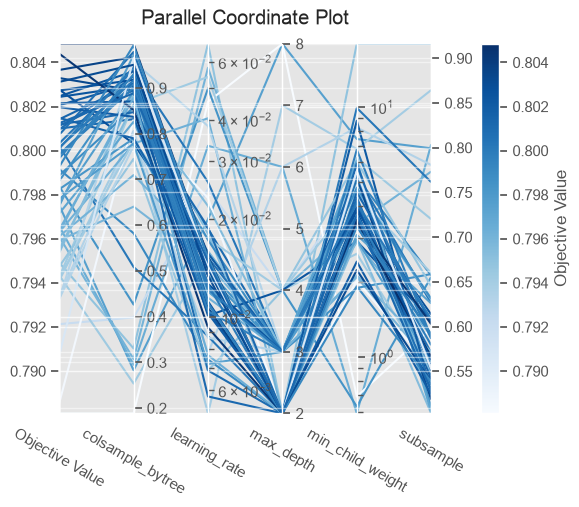

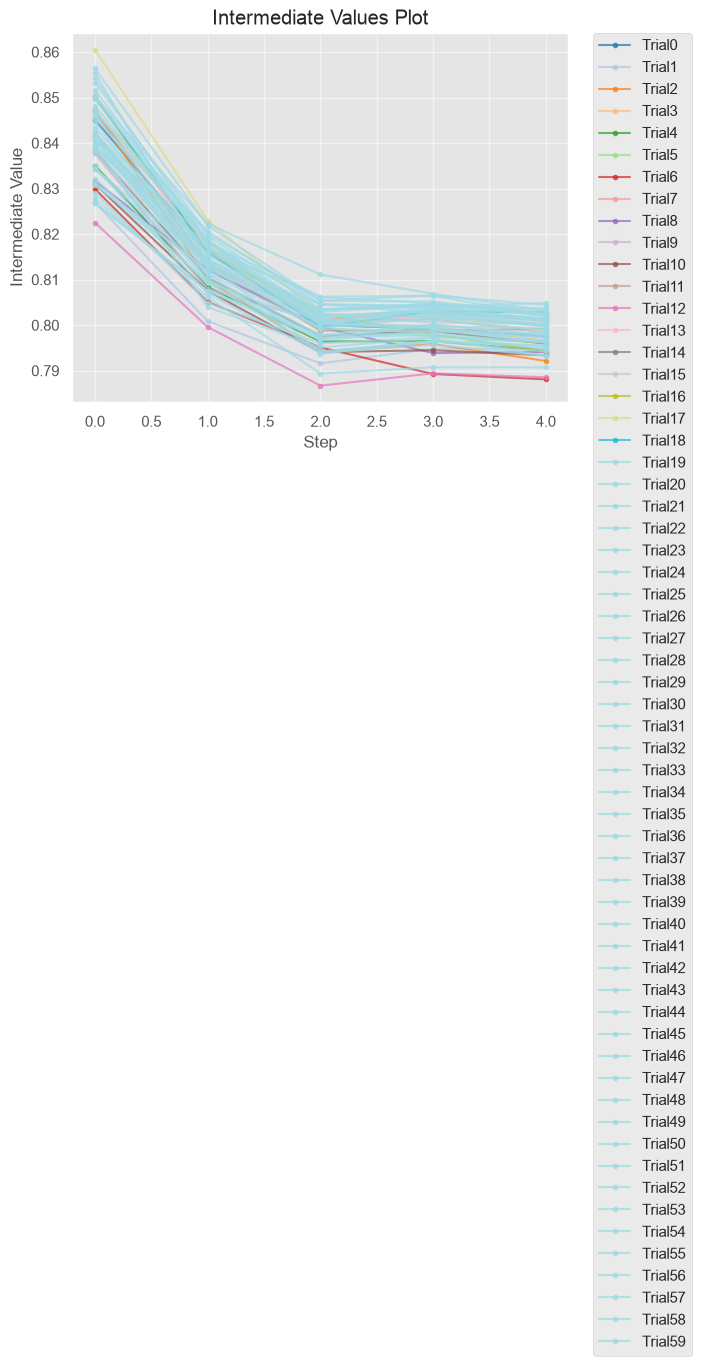

In [12]:
from optuna.visualization import matplotlib as ovm
ovm.plot_optimization_history(study_xgb); plt.title("Optimization history (XGBoost)"); plt.show()
ovm.plot_param_importances(study_xgb); plt.show()
ovm.plot_slice(study_xgb, params=["learning_rate", "max_depth", "min_child_weight", "colsample_bytree", "weight_power"]); plt.show()
ovm.plot_contour(study_xgb, params=["learning_rate", "max_depth"]); plt.show()
ovm.plot_parallel_coordinate(study_xgb, params=["learning_rate", "max_depth", "min_child_weight", "subsample", "colsample_bytree"]); plt.show()
ovm.plot_intermediate_values(study_xgb); plt.show()

### Interpretation of the optimisation

* **History.** The first trials are random (TPE start-up). After that the running best rises in steps, and later proposals cluster near the best region. This is the exploitation–exploration behaviour of TPE.
* **Parameter importance** (fANOVA) shows which hyperparameters explain most of the variance in the objective. Usually `learning_rate`, `max_depth`, and the class-weight exponent rank high, in line with the manual study.
* **Slice / contour plots** show the good region: moderate depth, small learning rates (compensated by many early-stopped trees), and column subsampling well below 1.
* **Intermediate values** show the pruned trials: they stop after one or two folds once they fall below the running median, which saves compute.
* The CV gain over the hand-chosen baseline is modest, about +0.005 to +0.01 macro-F1. Most of the improvement came from the data preparation, not the hyperparameters, which is typical for gradient boosting on tabular data.

Results are stored in `optuna_l2.db`. Re-running the cell continues the study instead of starting over.

## 7. Final XGBoost model and evaluation on the test set

The model is refit on the full training set with the best parameters (`n_estimators` = mean of the early-stopped iteration counts). We also keep its **out-of-fold** probabilities on the training set for the threshold search in section 8.

In [13]:
bp = dict(study_xgb.best_params)
xgb_weight_power = bp.pop("weight_power")
XGB_BEST = dict(bp, n_estimators=study_xgb.best_trial.user_attrs["n_estimators"],
                tree_method="hist", n_jobs=-1, random_state=0)

def cv_oof(make_model, weight_power):
    oof = np.zeros((len(y_train), N_CLASSES))
    for tr, va in cv_folds:
        m = make_model().fit(X_train.iloc[tr], y_train[tr],
                             sample_weight=compute_sample_weight("balanced", y_train[tr]) ** weight_power)
        oof[va] = m.predict_proba(X_train.iloc[va])
    return oof

oof_xgb = cv_oof(lambda: xgb.XGBClassifier(**XGB_BEST), xgb_weight_power)
final_xgb = xgb.XGBClassifier(**XGB_BEST).fit(
    X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train) ** xgb_weight_power)
proba_xgb = final_xgb.predict_proba(X_test)
pred_xgb = proba_xgb.argmax(1)
print("OOF CV macro-F1 (train):", round(U.macro_f1(y_train, oof_xgb.argmax(1)), 4))

OOF CV macro-F1 (train): 0.8031


=== XGBoost (argmax) on test set ===


,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted)
0,0.7799,0.7675,0.7812,0.7734,0.7809


              precision    recall  f1-score   support

       <100k      0.755     0.771     0.763        48
    100-130k      0.667     0.765     0.712       102
    130-180k      0.810     0.783     0.796       207
    180-250k      0.811     0.752     0.780       137
    250-400k      0.848     0.848     0.848        79
      >=400k      0.714     0.769     0.741        13

    accuracy                          0.780       586
   macro avg      0.768     0.781     0.773       586
weighted avg      0.784     0.780     0.781       586



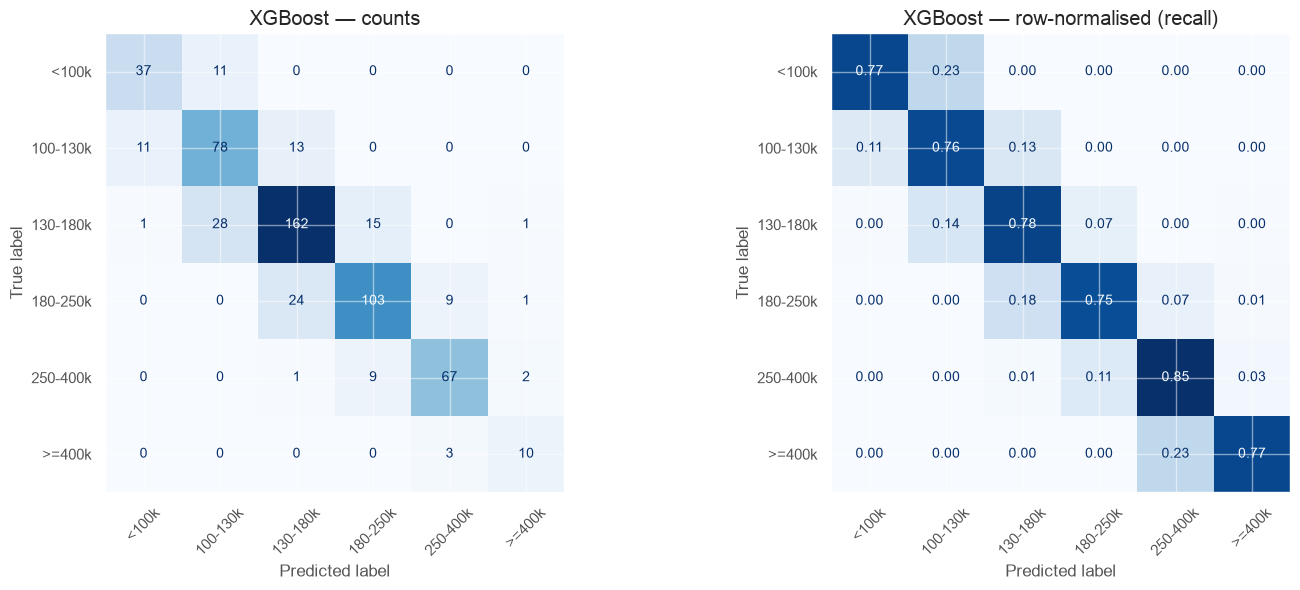

In [14]:
def report(y_true, y_pred, title):
    m = {"accuracy": accuracy_score(y_true, y_pred),
         "precision (macro)": precision_score(y_true, y_pred, average="macro"),
         "recall (macro)": recall_score(y_true, y_pred, average="macro"),
         "F1 (macro)": f1_score(y_true, y_pred, average="macro"),
         "F1 (weighted)": f1_score(y_true, y_pred, average="weighted")}
    print(f"=== {title} ===")
    display(pd.DataFrame([m]).round(4))
    print(classification_report(y_true, y_pred, target_names=U.CLASS_NAMES, digits=3))
    return m

def plot_confusion(y_true, y_pred, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, norm, t in [(axes[0], None, "counts"), (axes[1], "true", "row-normalised (recall)")]:
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, normalize=norm), display_labels=U.CLASS_NAMES).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format=".2f" if norm else "d")
        ax.set_title(f"{title} — {t}"); ax.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

metrics_xgb = report(y_test, pred_xgb, "XGBoost (argmax) on test set")
plot_confusion(y_test, pred_xgb, "XGBoost")

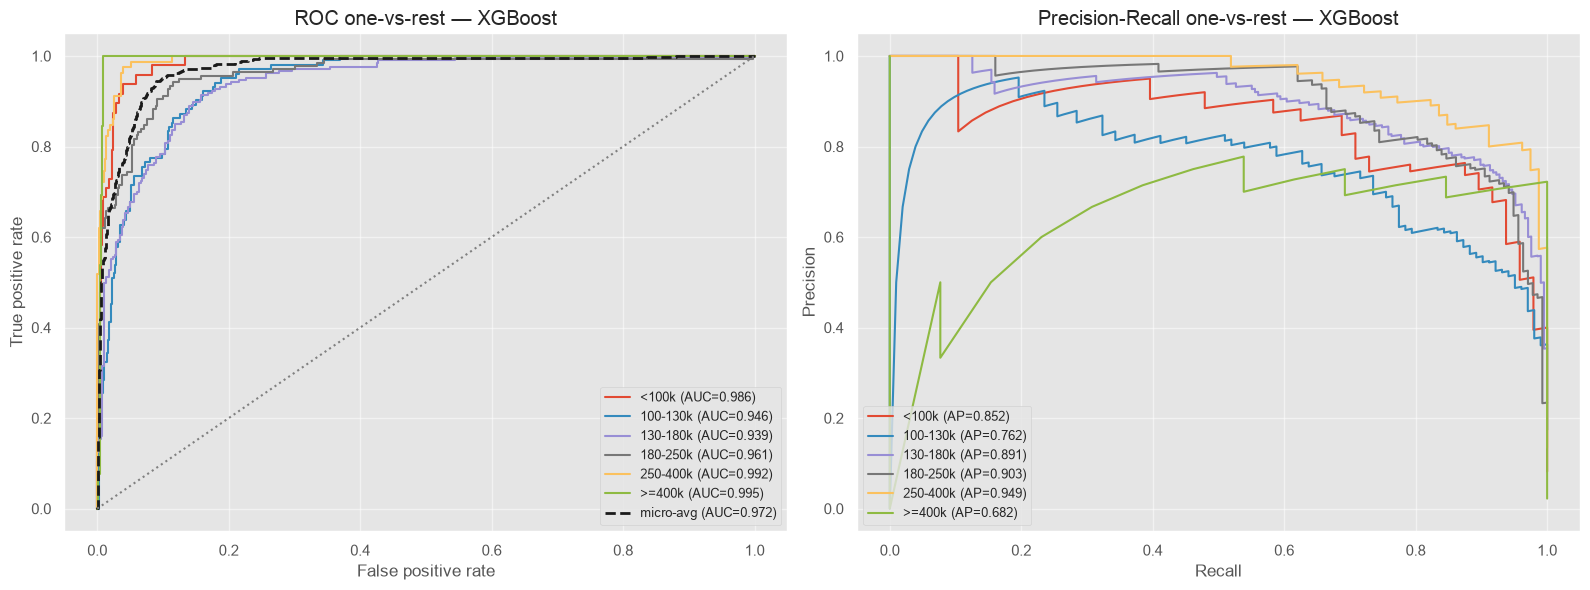

In [15]:
def plot_roc_pr(y_true, proba, title):
    Y = label_binarize(y_true, classes=range(N_CLASSES))
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for k, name in enumerate(U.CLASS_NAMES):
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
        prec, rec, _ = precision_recall_curve(Y[:, k], proba[:, k])
        axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(Y[:, k], proba[:, k]):.3f})")
    fpr, tpr, _ = roc_curve(Y.ravel(), proba.ravel())
    axes[0].plot(fpr, tpr, "k--", lw=2, label=f"micro-avg (AUC={auc(fpr, tpr):.3f})")
    axes[0].plot([0, 1], [0, 1], ":", color="grey")
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC one-vs-rest — {title}")
    axes[1].set(xlabel="Recall", ylabel="Precision", title=f"Precision-Recall one-vs-rest — {title}")
    for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=9)
    plt.tight_layout(); plt.show()

plot_roc_pr(y_test, proba_xgb, "XGBoost")

### Interpretation of the metrics

* The **confusion matrix is almost tridiagonal**. Nearly all errors fall into a *neighbouring* price class. A house that sells for 182k is not structurally different from one at 178k, so the bin edges cut through a continuous price distribution, and borderline houses decide most of the score.
* The **extreme classes** (`<100k`, `≥400k`) have the highest one-vs-rest AUC: very cheap or very expensive houses are easy to detect. Their F1 is limited by their small support. In the 20 % test set, `≥400k` has only about 13 houses, so a single error moves its F1 by several points.
* The **middle classes** (`100–130k`, `180–250k`) have the lowest AP. They are narrow intervals with neighbours on both sides.
* ROC-AUC is high for every class (> 0.9) because the one-vs-rest negatives are dominated by easy, far-away classes. The PR curves are a stricter view when classes are imbalanced, and they show the real difficulty in the middle classes.

### First tree, best tree, and feature importance

A multiclass XGBoost model with K = 6 classes builds **6 trees per boosting round**, one per class; their output is the class logit. Tree 0 is the first tree for class `<100k`. As the *best tree* we show the tree with the largest total split **gain** in the ensemble, i.e. the single tree that reduces the loss the most.

total trees: 3264  | best tree by gain: #11 (round 1, class '>=400k'), gain=472.3


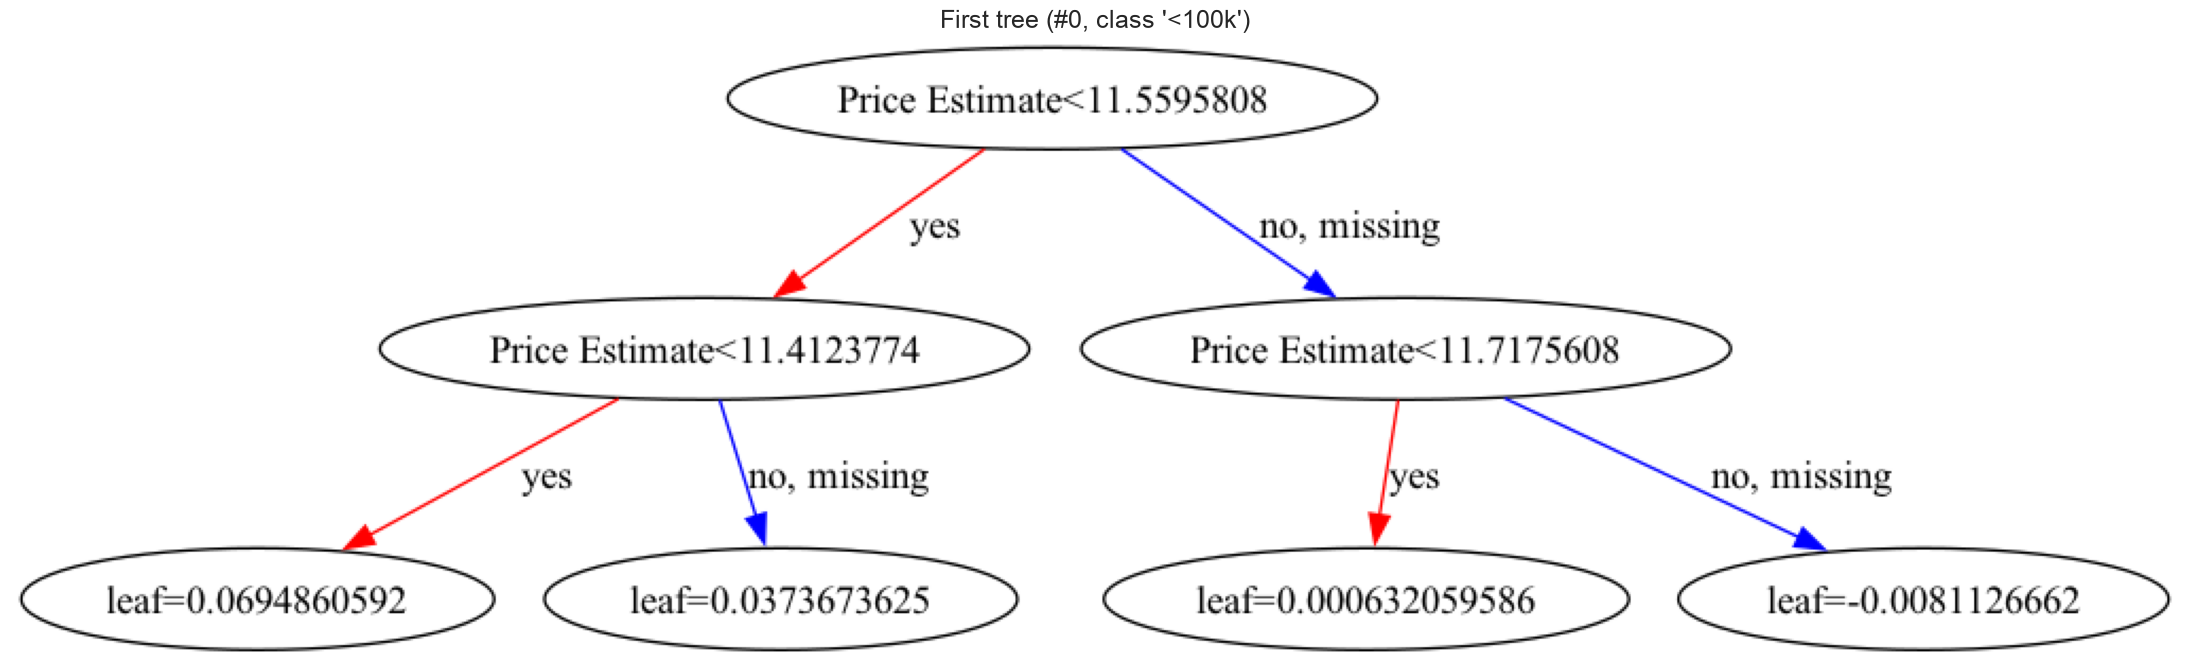

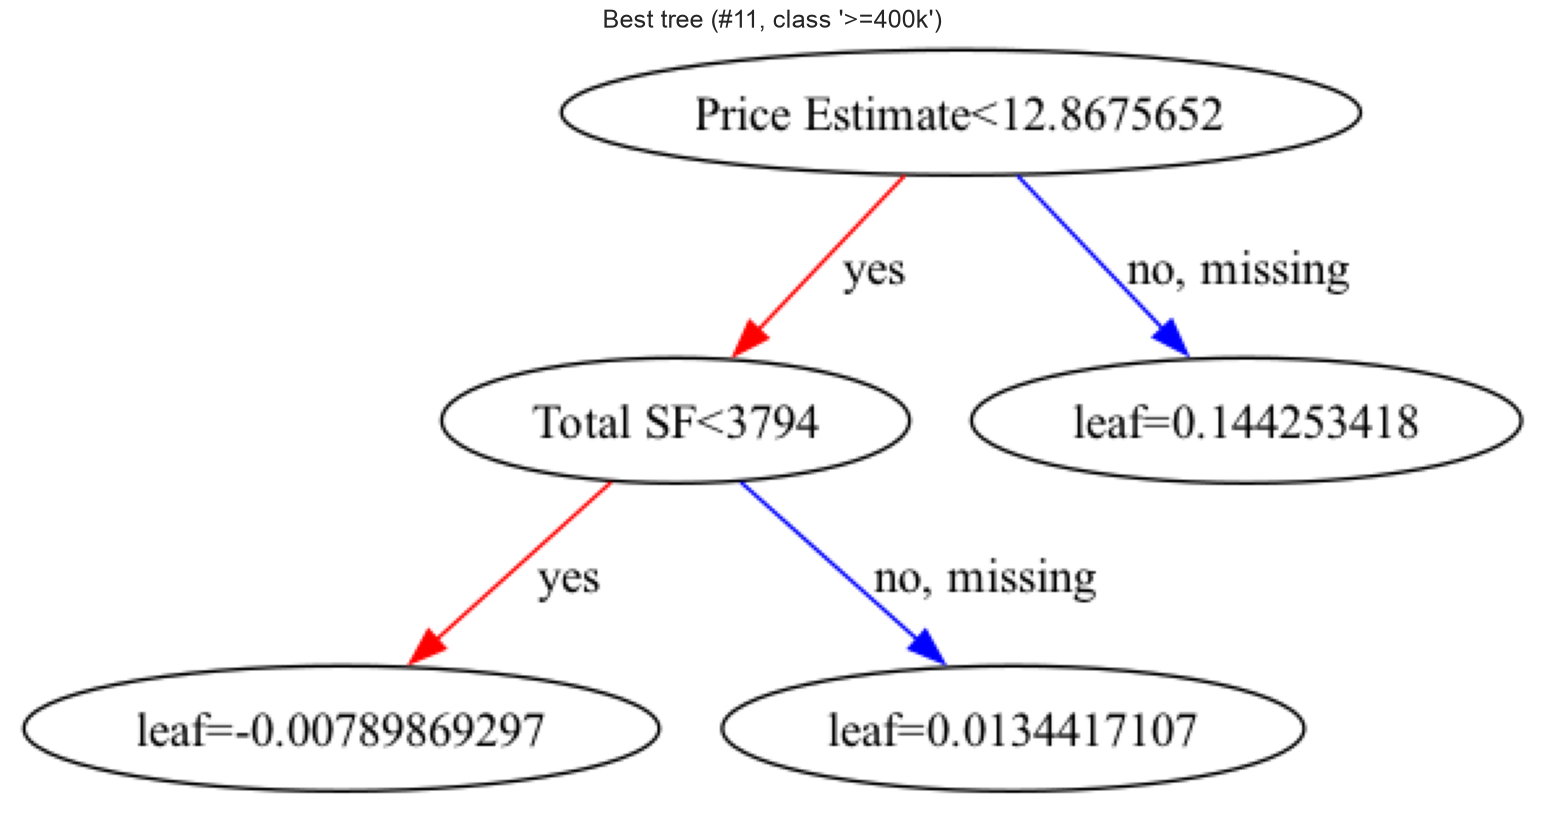

In [16]:
trees = final_xgb.get_booster().trees_to_dataframe()
tree_gain = trees[trees["Feature"] != "Leaf"].groupby("Tree")["Gain"].sum()
best_tree = int(tree_gain.idxmax())
print(f"total trees: {trees['Tree'].nunique()}  | best tree by gain: #{best_tree} "
      f"(round {best_tree // N_CLASSES}, class '{U.CLASS_NAMES[best_tree % N_CLASSES]}'), gain={tree_gain.max():.1f}")

for t, title in [(0, "First tree (#0, class '<100k')"), (best_tree, f"Best tree (#{best_tree}, class '{U.CLASS_NAMES[best_tree % N_CLASSES]}')")]:
    fig, ax = plt.subplots(figsize=(28, 10))
    xgb.plot_tree(final_xgb, tree_idx=t, ax=ax)
    ax.set_title(title, fontsize=18); plt.show()

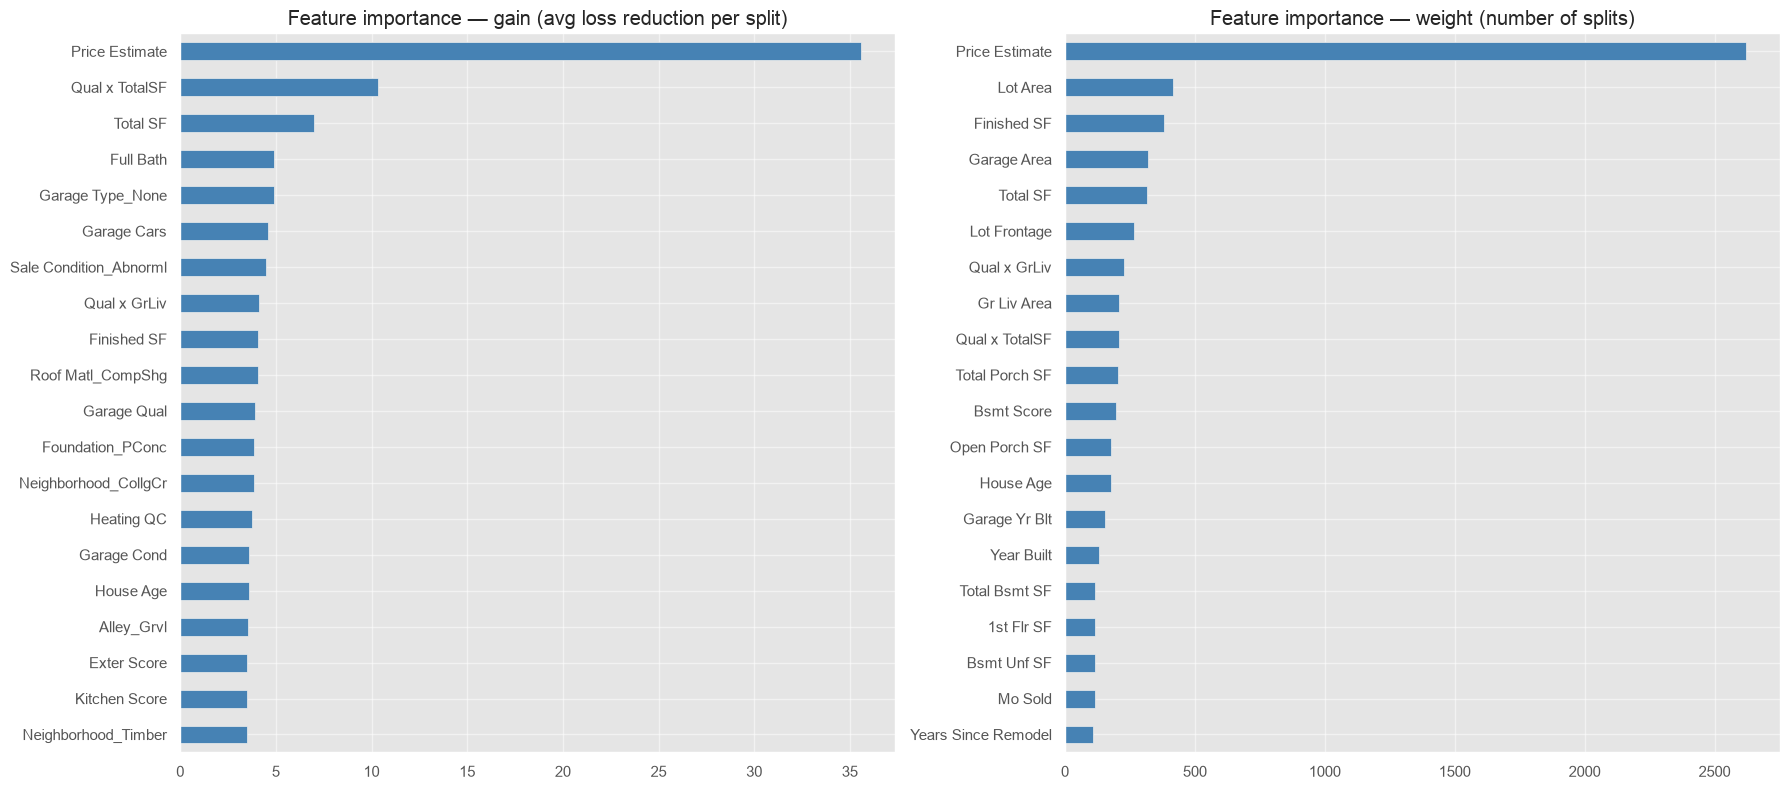

In [17]:
booster = final_xgb.get_booster()
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, imp in zip(axes, ["gain", "weight"]):
    s = pd.Series(booster.get_score(importance_type=imp)).sort_values().tail(20)
    s.plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"Feature importance — {imp} ({'avg loss reduction per split' if imp == 'gain' else 'number of splits'})")
plt.tight_layout(); plt.show()

* **First tree.** It splits on the strongest single signals, mainly the stacked `Price Estimate` and quality/size features. Its leaf values are large because no residual has been fitted yet.
* **Best tree.** It comes from an early round (rounds 0–1), before the large signals have been absorbed by earlier trees. Later trees only correct small residuals and have little gain.
* **Gain vs split (weight).** *Gain* shows how much a feature improves the loss on average when it is used. `Price Estimate`, `Overall Qual`, `Qual x TotalSF` dominate. *Weight* counts how often a feature is used. Continuous, fine-grained features (`Lot Area`, `Gr Liv Area`, `Garage Yr Blt`, `Bsmt Unf SF`) rank higher there because they offer many split points and are used for many small refinements. A feature can rank high on weight and low on gain; such features are typically used to fit noise.

## 8. Decision thresholds for the best macro-F1

`argmax` implicitly uses a threshold of 1/K and treats all classes the same. For macro-F1 that is not optimal: small classes benefit from a lower threshold (more recall), large classes from a higher one (more precision). We move the thresholds with per-class **probability multipliers** $w_k$, predicting $\hat y = \arg\max_k w_k\, p_k(x)$. Scaling $p_k$ by $w_k$ is equivalent to moving class $k$'s one-vs-rest threshold. The weights are found by coordinate ascent on the **out-of-fold training probabilities** (`U.optimize_class_weights`) and then applied once to the test set.

For comparison, the per-class PR curves also show the threshold that maximises each class's own F1 when the class is treated independently.

,class,threshold,precision,recall,F1
0,<100k,0.388,0.757,0.825,0.790
1,100-130k,0.308,0.650,0.850,0.737
2,130-180k,0.442,0.811,0.841,0.826
3,180-250k,0.330,0.750,0.889,0.814
4,250-400k,0.499,0.869,0.833,0.851
5,>=400k,0.396,0.839,0.922,0.879


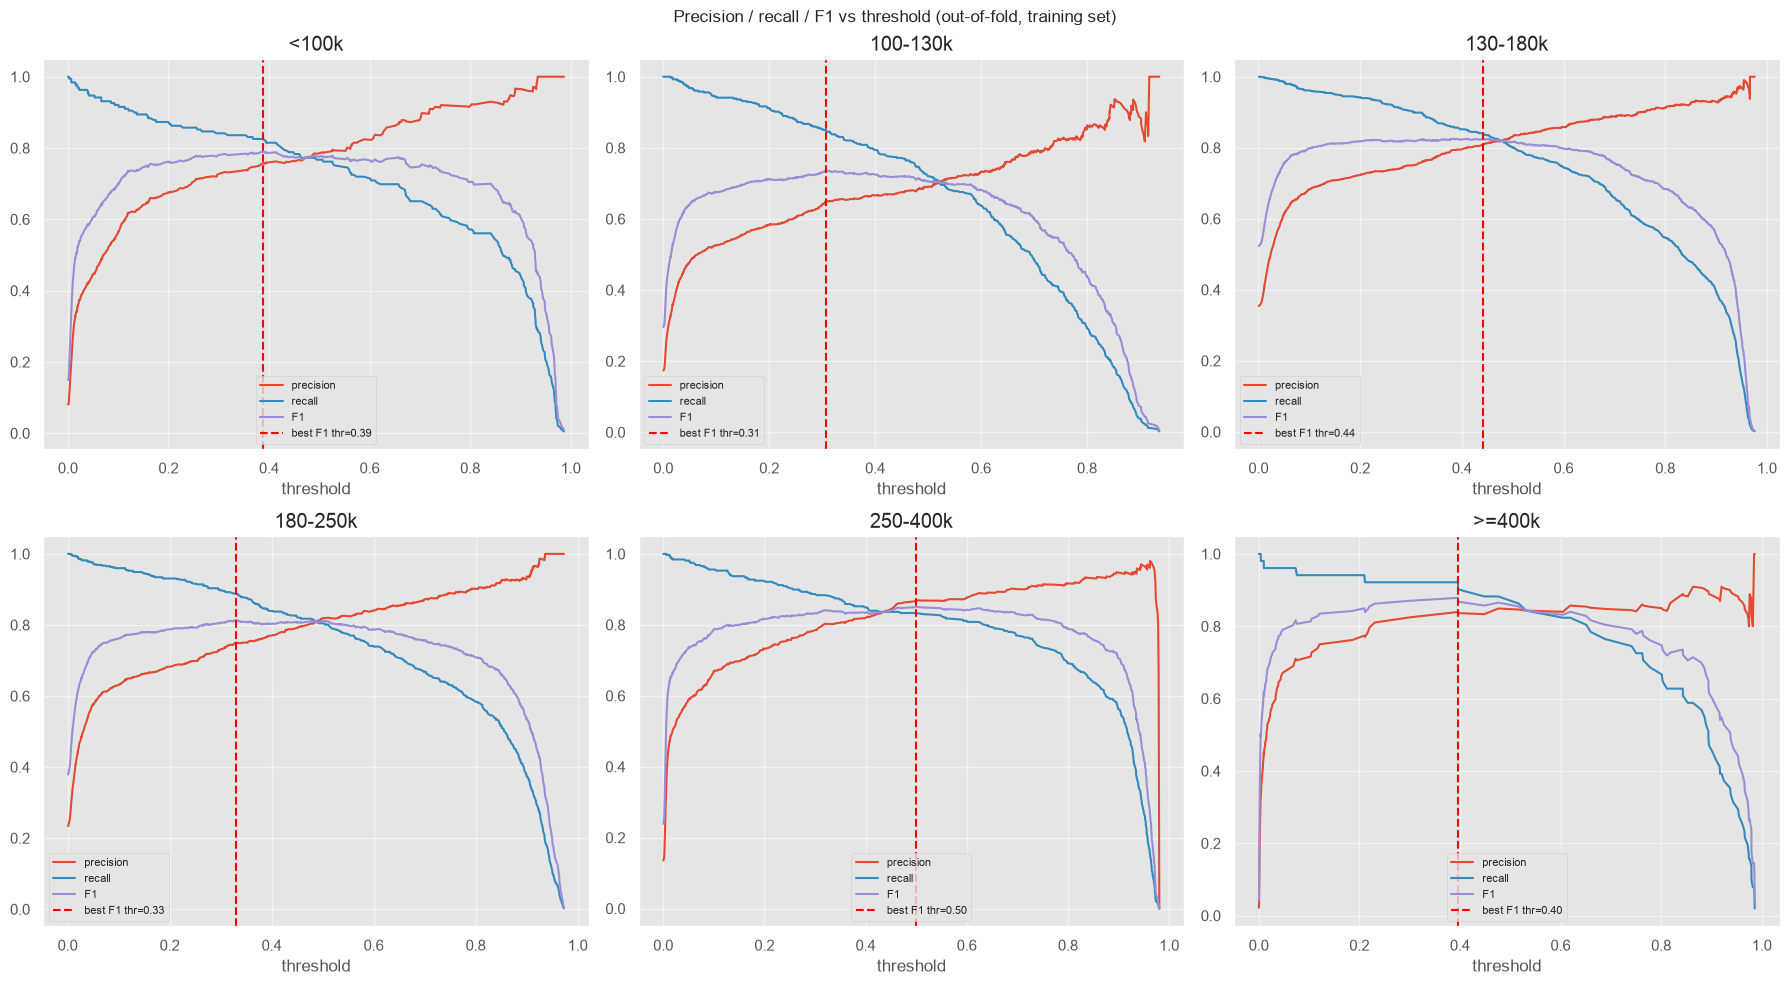

class multipliers: {'<100k': np.float64(1.3), '100-130k': np.float64(0.9), '130-180k': np.float64(0.8), '180-250k': np.float64(0.65), '250-400k': np.float64(0.65), '>=400k': np.float64(1.0)}
OOF macro-F1  argmax: 0.8031  ->  tuned: 0.8121
=== XGBoost with tuned thresholds on test set ===


,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted)
0,0.7799,0.7682,0.7884,0.7766,0.781


              precision    recall  f1-score   support

       <100k      0.755     0.833     0.792        48
    100-130k      0.655     0.765     0.706       102
    130-180k      0.809     0.778     0.793       207
    180-250k      0.828     0.737     0.780       137
    250-400k      0.848     0.848     0.848        79
      >=400k      0.714     0.769     0.741        13

    accuracy                          0.780       586
   macro avg      0.768     0.788     0.777       586
weighted avg      0.785     0.780     0.781       586



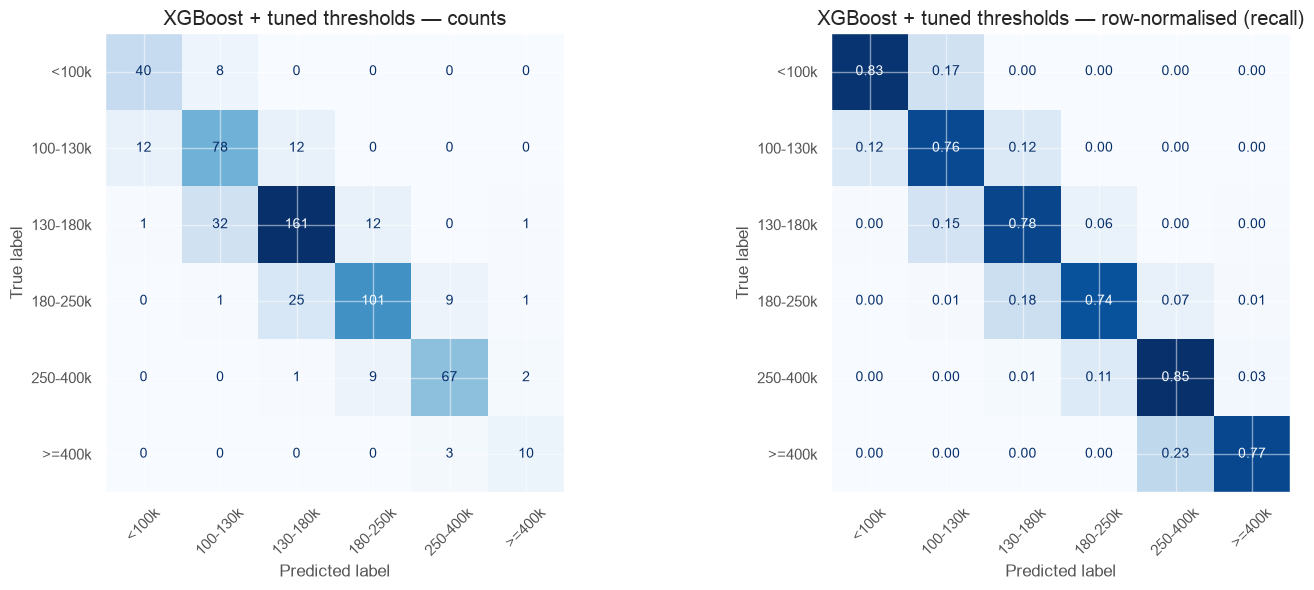

In [18]:
def best_f1_thresholds(y_true, proba):
    Y = label_binarize(y_true, classes=range(N_CLASSES)); rows = []
    for k in range(N_CLASSES):
        prec, rec, thr = precision_recall_curve(Y[:, k], proba[:, k])
        f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
        i = np.nanargmax(f1[:-1])
        rows.append({"class": U.CLASS_NAMES[k], "threshold": thr[i], "precision": prec[i], "recall": rec[i], "F1": f1[i]})
    return pd.DataFrame(rows)

thr_df = best_f1_thresholds(y_train, oof_xgb)
display(thr_df.round(3))

fig, axes = plt.subplots(2, 3, figsize=(18, 10)); Y = label_binarize(y_train, classes=range(N_CLASSES))
for k, ax in enumerate(axes.ravel()):
    prec, rec, thr = precision_recall_curve(Y[:, k], oof_xgb[:, k])
    ax.plot(thr, prec[:-1], label="precision"); ax.plot(thr, rec[:-1], label="recall")
    ax.plot(thr, 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None), label="F1")
    ax.axvline(thr_df.loc[k, "threshold"], color="red", ls="--", label=f"best F1 thr={thr_df.loc[k, 'threshold']:.2f}")
    ax.set_title(U.CLASS_NAMES[k]); ax.set_xlabel("threshold"); ax.legend(fontsize=8)
plt.suptitle("Precision / recall / F1 vs threshold (out-of-fold, training set)"); plt.tight_layout(); plt.show()

xgb_weights, oof_tuned = U.optimize_class_weights(oof_xgb, y_train)
print("class multipliers:", dict(zip(U.CLASS_NAMES, np.round(xgb_weights, 2))))
print(f"OOF macro-F1  argmax: {U.macro_f1(y_train, oof_xgb.argmax(1)):.4f}  ->  tuned: {oof_tuned:.4f}")
pred_xgb_tuned = U.predict_with_weights(proba_xgb, xgb_weights)
metrics_xgb_tuned = report(y_test, pred_xgb_tuned, "XGBoost with tuned thresholds on test set")
plot_confusion(y_test, pred_xgb_tuned, "XGBoost + tuned thresholds")

### Interpretation

* The per-class best-F1 thresholds are usually **below 0.5**, and especially low for the rare classes. Accepting a few more false positives buys a large gain in recall.
* The jointly optimised multipliers move borderline houses between neighbouring classes so that the *macro* average is maximised. Classes with weight > 1 receive more borderline houses (their recall rises), and classes with weight < 1 give some away.
* The gain on the OOF predictions is optimistic, because the weights were fitted on them. The **test-set** number is the honest estimate. The method is still useful because it costs nothing at inference time and was fitted without touching the test data.

## 9. Bonus — CatBoost vs. XGBoost (identical features)

We compared LightGBM and CatBoost on the same features in a preliminary experiment (stratified 5-fold, same stacking). CatBoost scored highest (≈0.796 vs LightGBM ≈0.783 vs XGBoost ≈0.791 untuned), so it is our bonus model.

**How the trees are built.**
| | XGBoost | CatBoost |
|---|---|---|
| Tree shape | depth-wise (level-wise) growth, each node chooses its own split → asymmetric trees | **oblivious (symmetric) trees**: *the same* split condition is used for every node of a level, so a depth-d tree is a lookup table with 2^d leaves |
| Split finding | second-order (gradient + Hessian) gain on histogram bins | score on quantised borders, plus random strength noise in split scoring |
| Boosting | standard: residuals computed on the same data the tree is fitted on | **ordered boosting**: residuals for a sample come from a model that has not seen that sample (random permutations) → less prediction shift / overfitting on small data |
| Multiclass | K separate trees per round (one per class) | **one** tree per round with a K-dimensional leaf value vector |
| Regularisation | λ, α, γ, min_child_weight, subsampling | l2_leaf_reg, depth, bagging_temperature, random_strength |

Symmetric trees are a strong regulariser: they cannot carve out tiny regions for single samples. Together with ordered boosting, this makes CatBoost well suited to a small dataset (about 2300 training rows) whose main difficulty is variance.

best CV macro-F1: 0.8084
best params: {'learning_rate': 0.013581340570643011, 'depth': 7, 'l2_leaf_reg': 14.520423384701903, 'random_strength': 0.11285379243326697, 'bagging_temperature': 1.7338886044802853, 'rsm': 0.8942940668636787, 'weight_power': 0.37544675653433174} | iterations: 2588


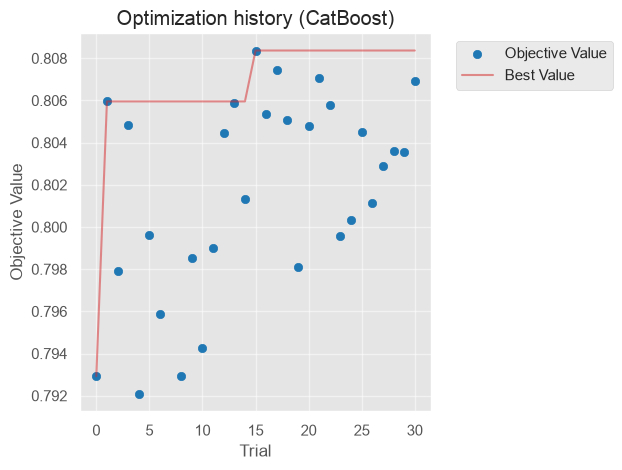

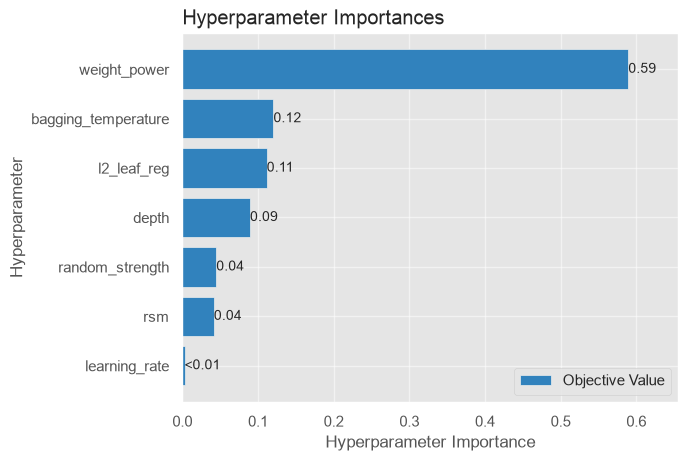

In [19]:
import catboost as cb

N_TRIALS_CB = 30

def cb_objective(trial):
    params = dict(
        iterations=3000, loss_function="MultiClass", random_seed=0, verbose=0,
        allow_writing_files=False, thread_count=-1, early_stopping_rounds=150,
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        depth=trial.suggest_int("depth", 3, 8),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 0.5, 30, log=True),
        random_strength=trial.suggest_float("random_strength", 0.1, 10, log=True),
        bagging_temperature=trial.suggest_float("bagging_temperature", 0.0, 2.0),
        rsm=trial.suggest_float("rsm", 0.2, 1.0),
    )
    weight_power = trial.suggest_float("weight_power", 0.0, 1.0)
    scores, iters = [], []
    for i, (tr, va) in enumerate(cv_folds):
        sw = compute_sample_weight("balanced", y_train[tr]) ** weight_power
        m = cb.CatBoostClassifier(**params).fit(X_train.iloc[tr], y_train[tr], sample_weight=sw,
                                                eval_set=(X_train.iloc[va], y_train[va]))
        scores.append(U.macro_f1(y_train[va], m.predict(X_train.iloc[va]).ravel().astype(int)))
        iters.append(m.get_best_iteration() + 1)
        trial.report(np.mean(scores), i)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("iterations", int(np.mean(iters)))
    return np.mean(scores)

study_cb = optuna.create_study(study_name="l2_catboost", storage=STORAGE, load_if_exists=True, direction="maximize",
                               sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8),
                               pruner=optuna.pruners.MedianPruner(n_startup_trials=6, n_warmup_steps=1))
remaining = N_TRIALS_CB - len([t for t in study_cb.trials if t.state.is_finished()])
if remaining > 0:
    study_cb.optimize(cb_objective, n_trials=remaining)
print("best CV macro-F1:", round(study_cb.best_value, 4))
print("best params:", study_cb.best_params, "| iterations:", study_cb.best_trial.user_attrs["iterations"])
ovm.plot_optimization_history(study_cb); plt.title("Optimization history (CatBoost)"); plt.show()
ovm.plot_param_importances(study_cb); plt.show()

=== CatBoost (argmax) on test set ===


,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted)
0,0.7952,0.7739,0.7904,0.7809,0.7961


              precision    recall  f1-score   support

       <100k      0.755     0.833     0.792        48
    100-130k      0.681     0.775     0.725       102
    130-180k      0.831     0.783     0.806       207
    180-250k      0.841     0.774     0.806       137
    250-400k      0.843     0.886     0.864        79
      >=400k      0.692     0.692     0.692        13

    accuracy                          0.795       586
   macro avg      0.774     0.790     0.781       586
weighted avg      0.800     0.795     0.796       586

=== CatBoost with tuned thresholds on test set ===


,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted)
0,0.7969,0.7838,0.7925,0.7867,0.7976


              precision    recall  f1-score   support

       <100k      0.755     0.833     0.792        48
    100-130k      0.681     0.775     0.725       102
    130-180k      0.831     0.783     0.806       207
    180-250k      0.841     0.774     0.806       137
    250-400k      0.845     0.899     0.871        79
      >=400k      0.750     0.692     0.720        13

    accuracy                          0.797       586
   macro avg      0.784     0.793     0.787       586
weighted avg      0.801     0.797     0.798       586



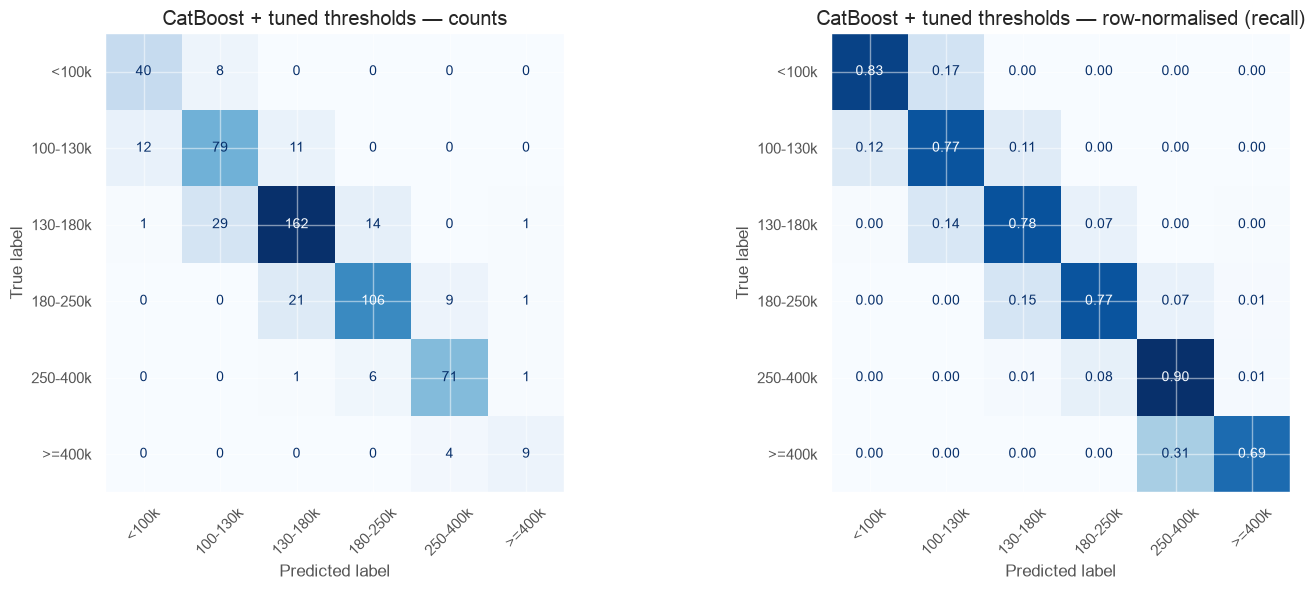

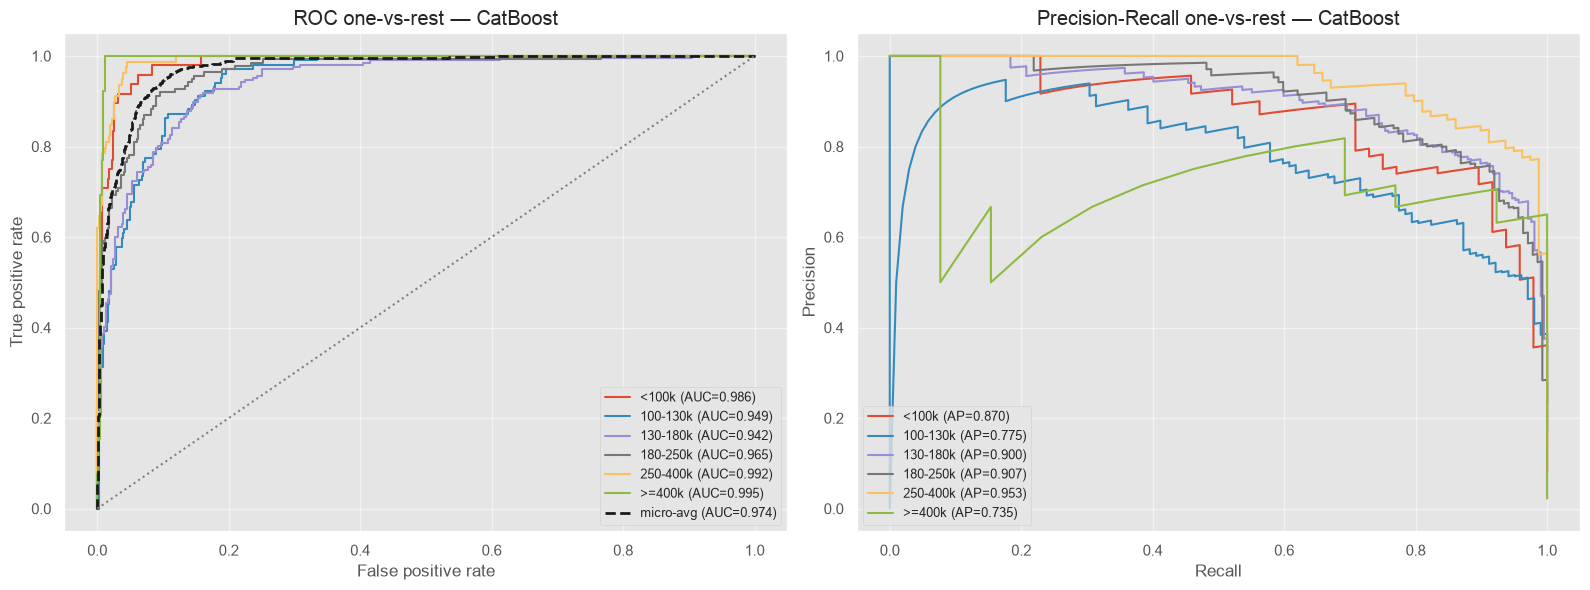

In [20]:
cbp = dict(study_cb.best_params)
cb_weight_power = cbp.pop("weight_power")
CB_BEST = dict(cbp, iterations=study_cb.best_trial.user_attrs["iterations"], loss_function="MultiClass",
               random_seed=0, verbose=0, allow_writing_files=False, thread_count=-1)

oof_cb = cv_oof(lambda: cb.CatBoostClassifier(**CB_BEST), cb_weight_power)
final_cb = cb.CatBoostClassifier(**CB_BEST).fit(
    X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train) ** cb_weight_power)
proba_cb = final_cb.predict_proba(X_test)
cb_weights, _ = U.optimize_class_weights(oof_cb, y_train)

metrics_cb = report(y_test, proba_cb.argmax(1), "CatBoost (argmax) on test set")
pred_cb_tuned = U.predict_with_weights(proba_cb, cb_weights)
metrics_cb_tuned = report(y_test, pred_cb_tuned, "CatBoost with tuned thresholds on test set")
plot_confusion(y_test, pred_cb_tuned, "CatBoost + tuned thresholds")
plot_roc_pr(y_test, proba_cb, "CatBoost")

### Tree structure: CatBoost oblivious trees vs XGBoost trees

CatBoost's `plot_tree` shows that each level uses **one** split condition for all nodes; the tree is perfectly symmetric. Each leaf holds a vector of 6 class values. The XGBoost trees in section 7 are asymmetric: each node picks its own feature and threshold, and each tree belongs to a single class.

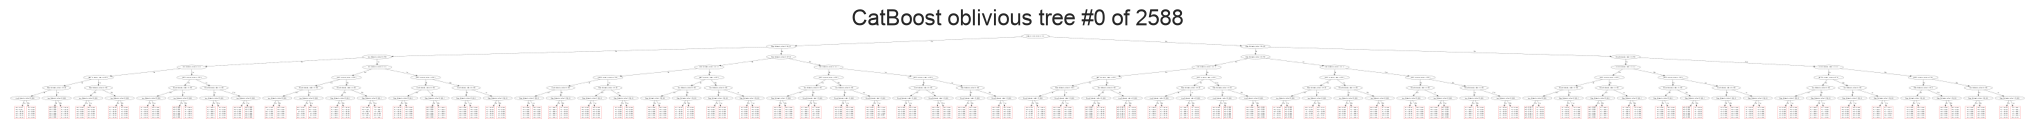

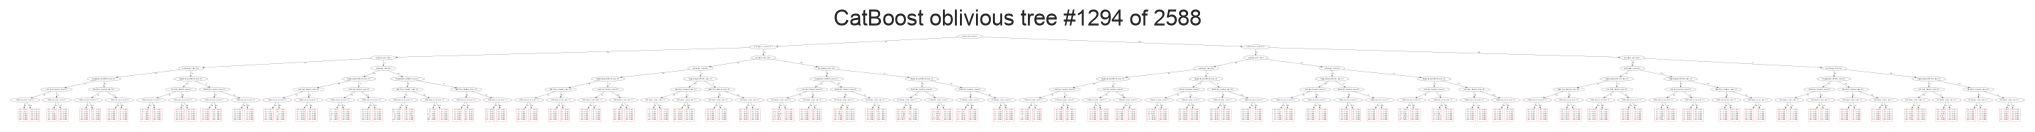

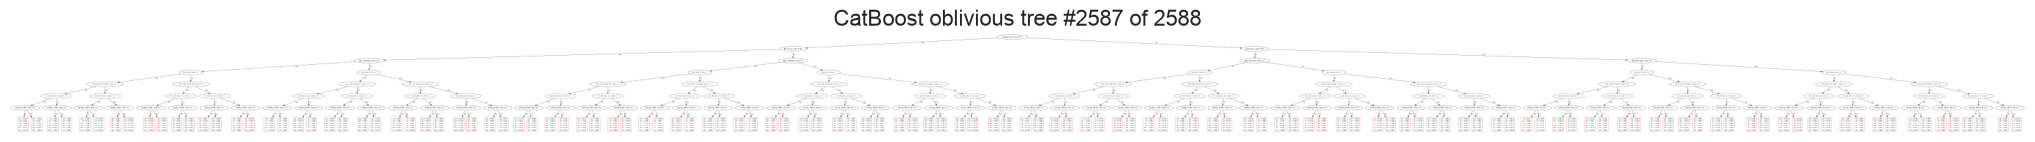

In [21]:
from catboost import Pool
import io
from PIL import Image

pool_train = Pool(X_train, y_train)
cb_tree_gain = []
for t in [0, final_cb.tree_count_ // 2, final_cb.tree_count_ - 1]:
    g = final_cb.plot_tree(tree_idx=t, pool=pool_train)
    g.attr(size="30,8")
    img = Image.open(io.BytesIO(g.pipe(format="png")))
    plt.figure(figsize=(26, 7)); plt.imshow(img); plt.axis("off")
    plt.title(f"CatBoost oblivious tree #{t} of {final_cb.tree_count_}", fontsize=16); plt.show()

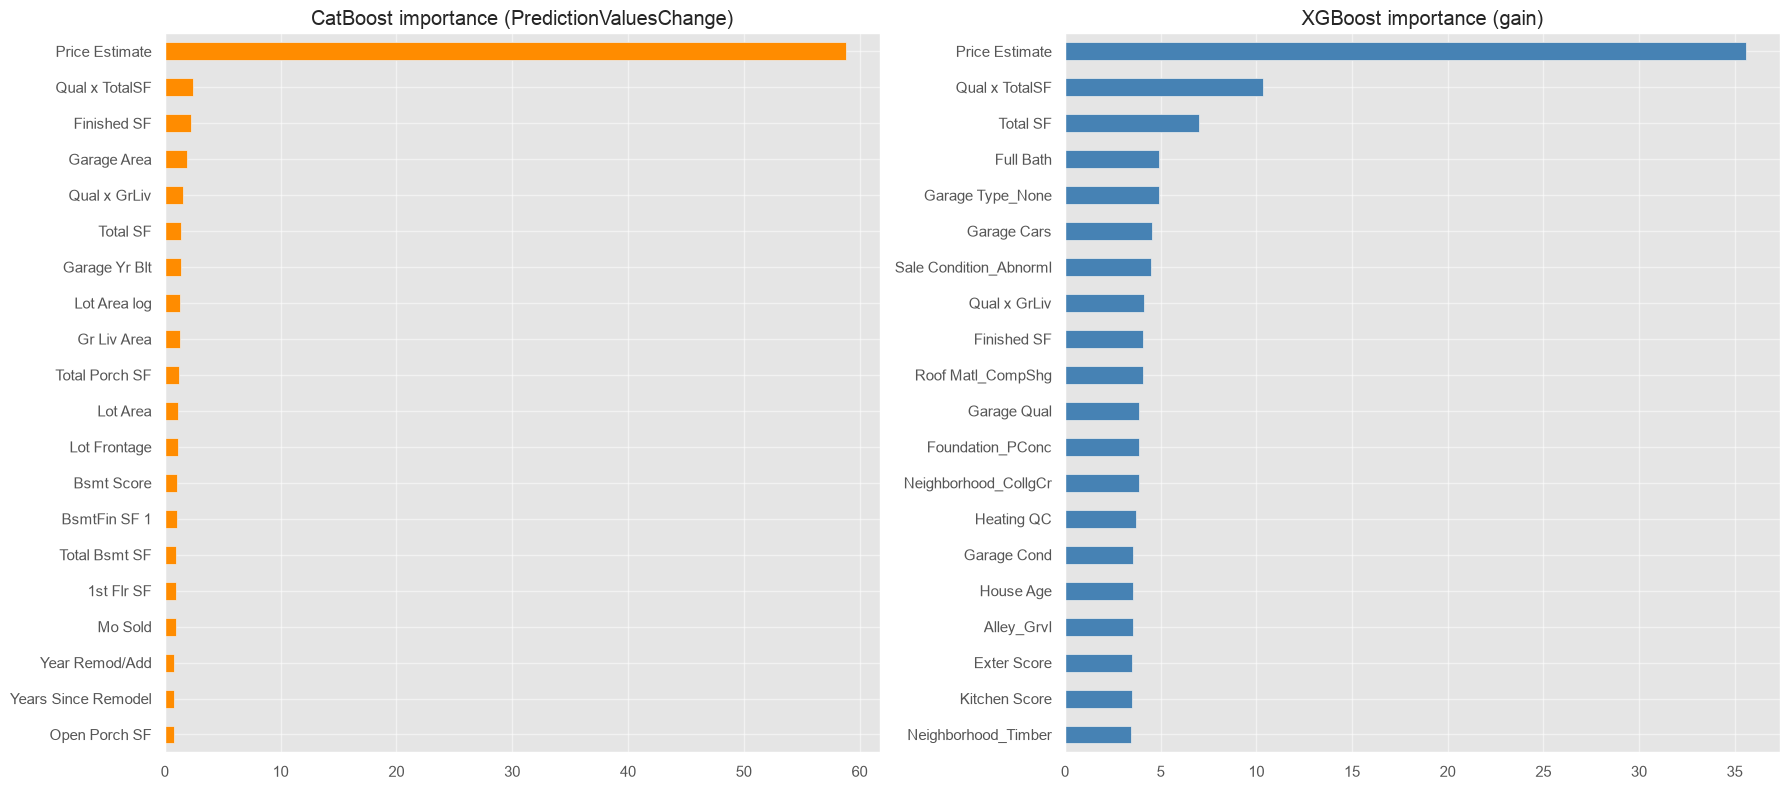

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
cb_imp = pd.Series(final_cb.get_feature_importance(type="PredictionValuesChange"), index=X_train.columns).sort_values().tail(20)
cb_imp.plot.barh(ax=axes[0], color="darkorange"); axes[0].set_title("CatBoost importance (PredictionValuesChange)")
xgb_gain = pd.Series(final_xgb.get_booster().get_score(importance_type="gain")).sort_values().tail(20)
xgb_gain.plot.barh(ax=axes[1], color="steelblue"); axes[1].set_title("XGBoost importance (gain)")
plt.tight_layout(); plt.show()

### Learning process

We train both tuned models once more on the training set with the test set as an evaluation set, and record the multiclass log-loss per boosting round. This shows how quickly each model learns and when it starts to overfit.

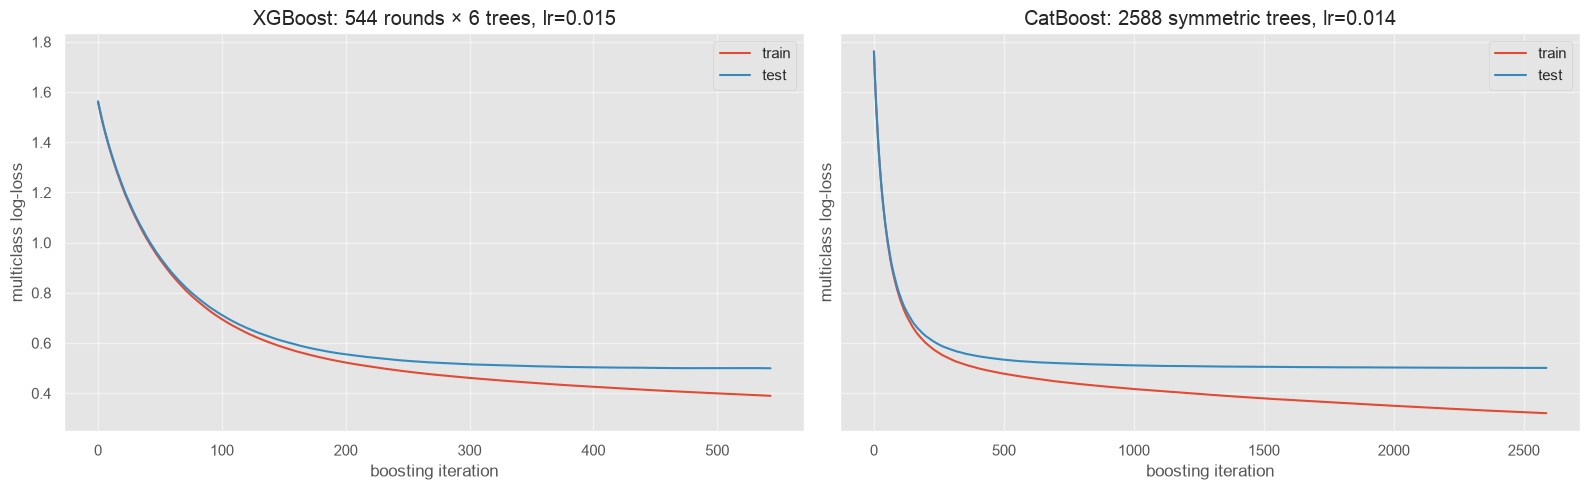

In [23]:
lc_xgb = xgb.XGBClassifier(**{**XGB_BEST, "eval_metric": "mlogloss"}).fit(
    X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train) ** xgb_weight_power,
    eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False).evals_result()
lc_cb = cb.CatBoostClassifier(**CB_BEST).fit(
    X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train) ** cb_weight_power,
    eval_set=(X_test, y_test)).get_evals_result()

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
axes[0].plot(lc_xgb["validation_0"]["mlogloss"], label="train"); axes[0].plot(lc_xgb["validation_1"]["mlogloss"], label="test")
axes[0].set_title(f"XGBoost: {XGB_BEST['n_estimators']} rounds × 6 trees, lr={XGB_BEST['learning_rate']:.3f}")
axes[1].plot(lc_cb["learn"]["MultiClass"], label="train"); axes[1].plot(lc_cb["validation"]["MultiClass"], label="test")
axes[1].set_title(f"CatBoost: {CB_BEST['iterations']} symmetric trees, lr={CB_BEST['learning_rate']:.3f}")
for ax in axes: ax.set_xlabel("boosting iteration"); ax.set_ylabel("multiclass log-loss"); ax.legend()
plt.tight_layout(); plt.show()

* **XGBoost** quickly reduces the *training* loss towards 0. Its unconstrained, asymmetric trees can isolate individual houses, so the train/test gap widens steadily.
* **CatBoost** learns more slowly per iteration and its training loss stays clearly higher. Symmetric trees plus ordered boosting work as a regulariser, so the train/test gap is smaller. With only about 2300 training rows, lower variance is worth more than the extra flexibility.
* The **test loss** of both models flattens at a similar level. The early-stopped iteration counts found during tuning are near the minimum of the test curve.

### Ensemble

XGBoost and CatBoost make partly *different* errors because their trees are built differently. Averaging their probabilities reduces variance further. The thresholds for the ensemble are again tuned on the averaged **out-of-fold** probabilities only.

=== XGBoost + CatBoost ensemble (argmax) ===


,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted)
0,0.7918,0.7708,0.7818,0.7754,0.7929


              precision    recall  f1-score   support

       <100k      0.745     0.792     0.768        48
    100-130k      0.672     0.765     0.716       102
    130-180k      0.827     0.787     0.807       207
    180-250k      0.836     0.781     0.808       137
    250-400k      0.852     0.873     0.863        79
      >=400k      0.692     0.692     0.692        13

    accuracy                          0.792       586
   macro avg      0.771     0.782     0.775       586
weighted avg      0.796     0.792     0.793       586

=== XGBoost + CatBoost ensemble with tuned thresholds ===


,accuracy,precision (macro),recall (macro),F1 (macro),F1 (weighted)
0,0.7816,0.7782,0.7918,0.7815,0.7838


              precision    recall  f1-score   support

       <100k      0.791     0.708     0.747        48
    100-130k      0.624     0.814     0.706       102
    130-180k      0.834     0.754     0.792       207
    180-250k      0.817     0.781     0.799       137
    250-400k      0.870     0.848     0.859        79
      >=400k      0.733     0.846     0.786        13

    accuracy                          0.782       586
   macro avg      0.778     0.792     0.781       586
weighted avg      0.793     0.782     0.784       586



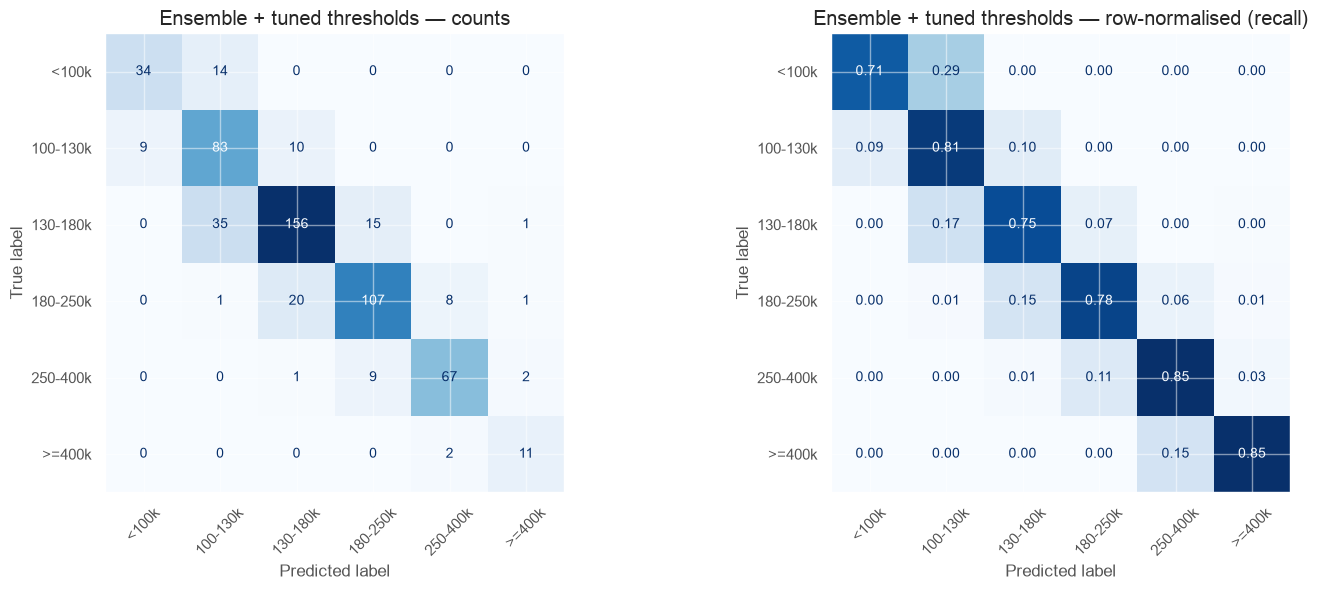

In [24]:
oof_ens = (oof_xgb + oof_cb) / 2
proba_ens = (proba_xgb + proba_cb) / 2
ens_weights, _ = U.optimize_class_weights(oof_ens, y_train)
pred_ens_tuned = U.predict_with_weights(proba_ens, ens_weights)
metrics_ens = report(y_test, proba_ens.argmax(1), "XGBoost + CatBoost ensemble (argmax)")
metrics_ens_tuned = report(y_test, pred_ens_tuned, "XGBoost + CatBoost ensemble with tuned thresholds")
plot_confusion(y_test, pred_ens_tuned, "Ensemble + tuned thresholds")

## 10. Summary

In [25]:
def oof_f1(p, w=None):
    return U.macro_f1(y_train, p.argmax(1) if w is None else U.predict_with_weights(p, w))

summary = pd.DataFrame([
    {"model": "XGBoost (tuned)",                    "CV OOF macro-F1": oof_f1(oof_xgb), **metrics_xgb},
    {"model": "XGBoost (tuned) + thresholds",       "CV OOF macro-F1": oof_f1(oof_xgb, xgb_weights), **metrics_xgb_tuned},
    {"model": "CatBoost (tuned)",                   "CV OOF macro-F1": oof_f1(oof_cb), **metrics_cb},
    {"model": "CatBoost (tuned) + thresholds",      "CV OOF macro-F1": oof_f1(oof_cb, cb_weights), **metrics_cb_tuned},
    {"model": "XGB + CatBoost ensemble",            "CV OOF macro-F1": oof_f1(oof_ens), **metrics_ens},
    {"model": "XGB + CatBoost ensemble + thresholds","CV OOF macro-F1": oof_f1(oof_ens, ens_weights), **metrics_ens_tuned},
]).set_index("model")
summary.columns = ["CV OOF macro-F1 (train)"] + [f"test {c}" for c in summary.columns[1:]]
display(summary.round(4).style.highlight_max(axis=0, color="#c6efce"))

,CV OOF macro-F1 (train),test accuracy,test precision (macro),test recall (macro),test F1 (macro),test F1 (weighted)
model,,,,,,
XGBoost (tuned),0.803100,0.779900,0.767500,0.781200,0.773400,0.780900
XGBoost (tuned) + thresholds,0.812100,0.779900,0.768200,0.788400,0.776600,0.781000
CatBoost (tuned),0.808000,0.795200,0.773900,0.790400,0.780900,0.796100
CatBoost (tuned) + thresholds,0.809700,0.796900,0.783800,0.792500,0.786700,0.797600
XGB + CatBoost ensemble,0.802200,0.791800,0.770800,0.781800,0.775400,0.792900
XGB + CatBoost ensemble + thresholds,0.808300,0.781600,0.778200,0.791800,0.781500,0.783800


## Conclusions

1. **Data preparation matters most.** Each step improves the stratified 5-fold macro-F1 of the same XGBoost model: going from naive label encoding to ordinal mapping + one-hot, then adding domain features, and finally adding the stacked `Price Estimate` feature. Together they add about 5 points of macro-F1. Hyperparameter tuning then adds about one more point.
2. **The target is ordinal.** The price classes are ordered intervals of a continuous variable. Most errors are between neighbouring classes, and a regression estimate of the price, used as a feature, helps the multiclass model the most.
3. **Class imbalance.** Balanced (or partly balanced, as chosen by Optuna) sample weights and macro-F1-optimised decision thresholds both increase recall on the small classes `<100k` and `≥400k`, which is exactly what macro-F1 rewards.
4. **Evaluation protocol.** Stratification is essential with a 2 % class. A 10 % hold-out set is too noisy to compare models, so model selection used stratified 5-fold CV, and the 20 % test set was evaluated only once at the end. k = 10 gives a slightly less biased but more variable and more expensive estimate than k = 5.
5. **Bias–variance.** All boosted models fit the training data almost perfectly. The limit is variance from about 2300 rows and borderline houses near the bin edges. Regularisation (shallow trees, subsampling, early stopping), CatBoost's symmetric trees, and averaging two different models all reduce variance, and each of them raised the macro-F1.